## **Project Title :**

Hydraulic Accumulator Condition Prediction


## Project Overview

This project aims to develop a machine learning classification model for predicting the condition of a hydraulic accumulator using sensor measurements collected from a hydraulic test system.

The project follows an end-to-end machine learning workflow including data understanding, exploratory data analysis, feature analysis, preprocessing, model development, hyperparameter tuning, evaluation, and interpretation.

The target variable represents four different accumulator pressure conditions:
- 130: Optimal pressure
- 115: Slightly reduced pressure
- 100: Severely reduced pressure
- 90: Close to failure

The dataset is based on the Condition Monitoring of Hydraulic Systems dataset provided by the UCI Machine Learning Repository.

## 1. Problem Statement

Hydraulic systems are widely used in industrial applications, and monitoring the condition of their components is important for reliable operation.

In this project, sensor measurements from a hydraulic test system are used to classify the condition of a hydraulic accumulator into four operating-condition levels.

### Objective

To develop and evaluate machine learning classification models that can identify the condition of a hydraulic accumulator from cycle-level sensor measurements.

### Machine Learning Task

This is a multiclass classification problem with four target classes:

90, 100, 115, and 130.

## Importing Libraries

In [1]:
# Data handling and visualization
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Display tools
from IPython.display import display

# Statistical analysis
from scipy.stats import spearmanr

# Machine learning: preprocessing and feature selection
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.feature_selection import f_classif, mutual_info_classif

# Machine learning: models
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.dummy import DummyClassifier
from sklearn.base import clone

# Model evaluation
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    confusion_matrix
)

## Load the Dataset

The engineered dataset contains cycle-level statistical features extracted from the raw hydraulic sensor measurements.

Each row represents one complete hydraulic operating cycle, while the columns contain statistical features derived from the sensor signals.

The dataset will be loaded into a Pandas DataFrame for further analysis.

In [2]:

# Load the dataset

df = pd.read_csv("../data/hydraulic_accumulator_initial_features.csv")

print("Dataset loaded successfully.")


Dataset loaded successfully.


In [3]:
# Convert the target to integer class labels

df["Accumulator_Condition"] = (
    df["Accumulator_Condition"].astype(int)
)

print("Target data type:", df["Accumulator_Condition"].dtype)
print("Target classes:", sorted(df["Accumulator_Condition"].unique()))

Target data type: int64
Target classes: [np.int64(90), np.int64(100), np.int64(115), np.int64(130)]



## 3. Dataset Understanding

Before performing exploratory data analysis, we examine the structure of the dataset to understand its observations, features, and target variable.

Each row represents one complete hydraulic operating cycle. The sensor features summarize measurements recorded during that cycle.


In [4]:

# Display the first five observations

df.head()


,Cycle,PS1_mean,PS1_std,PS1_min,PS1_max,PS1_range,PS1_rms,PS2_mean,PS2_std,PS2_min,...,TS4_max,TS4_range,TS4_rms,VS1_mean,VS1_std,VS1_min,VS1_max,VS1_range,VS1_rms,Accumulator_Condition
0,1,160.67350,13.938147,145.83,191.51,45.679993,161.27692,109.466920,47.110580,0.0,...,33.594,3.231001,31.764551,0.576950,0.026852,0.532,0.624,0.092,0.577574,130
1,2,160.60332,14.117792,145.73,191.47,45.740005,161.22264,109.354900,47.041687,0.0,...,35.148,1.500000,34.496567,0.565850,0.027013,0.524,0.626,0.102,0.566494,130
2,3,160.34772,14.191435,145.37,191.41,46.040010,160.97450,109.158850,46.988144,0.0,...,36.141,1.042999,35.647343,0.576533,0.036422,0.529,0.662,0.133,0.577683,130
3,4,160.18808,14.226617,145.14,191.34,46.199997,160.81860,109.064810,46.968304,0.0,...,36.988,0.882999,36.580390,0.569267,0.033184,0.527,0.645,0.118,0.570233,130
4,5,160.00047,14.275245,144.95,191.41,46.460007,160.63603,108.931435,46.871037,0.0,...,37.781,0.788998,37.428654,0.577367,0.033203,0.524,0.660,0.136,0.578321,130



### 3.1 Dataset Dimensions

We inspect the number of observations and columns to confirm that the engineered dataset has the expected structure.


In [5]:

# Check the number of rows and columns

print("Number of cycles:", df.shape[0])
print("Number of columns:", df.shape[1])
print("Number of sensor-derived features:", df.shape[1] - 2)


Number of cycles: 2205
Number of columns: 86
Number of sensor-derived features: 84



### 3.2 Dataset Structure and Data Types

We examine the data types and non-null counts of the columns. This helps identify unexpected text columns, missing observations, or other inconsistencies before further analysis.


In [6]:

# Inspect column data types and non-null counts

df.info()


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2205 entries, 0 to 2204
Data columns (total 86 columns):
 #   Column                 Non-Null Count  Dtype  
---  ------                 --------------  -----  
 0   Cycle                  2205 non-null   int64  
 1   PS1_mean               2205 non-null   float64
 2   PS1_std                2205 non-null   float64
 3   PS1_min                2205 non-null   float64
 4   PS1_max                2205 non-null   float64
 5   PS1_range              2205 non-null   float64
 6   PS1_rms                2205 non-null   float64
 7   PS2_mean               2205 non-null   float64
 8   PS2_std                2205 non-null   float64
 9   PS2_min                2205 non-null   float64
 10  PS2_max                2205 non-null   float64
 11  PS2_range              2205 non-null   float64
 12  PS2_rms                2205 non-null   float64
 13  PS3_mean               2205 non-null   float64
 14  PS3_std                2205 non-null   float64
 15  PS3_

In [7]:

# Count missing values in each column

missing_values = df.isnull().sum()

print("Total missing values:", missing_values.sum())

# Display only columns containing missing values
missing_values[missing_values > 0]


Total missing values: 0


Series([], dtype: int64)


### 3.3 Duplicate Record Analysis

Duplicate records are checked to identify repeated observations. This helps us understand the dataset's quality before performing exploratory data analysis.


In [8]:

# Count duplicate rows

duplicate_count = df.duplicated().sum()

print("Number of duplicate rows:", duplicate_count)



Number of duplicate rows: 0



### 3.4 Infinite Value Analysis

Infinite values are checked because they can cause errors in statistical calculations and machine learning algorithms.


In [9]:


# Select numerical columns and check for infinite values

numeric_df = df.select_dtypes(include=np.number)

infinite_count = np.isinf(numeric_df).sum().sum()

print("Total infinite values:", infinite_count)


Total infinite values: 0



### 3.5 Descriptive Statistics

Descriptive statistics help us understand the scale and variability of each numerical column. We examine the mean, standard deviation, minimum, maximum, and quartiles before investigating individual features.


In [10]:

# Generate a summary of numerical columns

df.describe().T


,count,mean,std,min,25%,50%,75%,max
Cycle,2205.0,1103.000000,636.672993,1.000000,552.000000,1103.000000,1654.000000,2205.000000
PS1_mean,2205.0,160.485315,4.699424,155.391540,158.100200,158.960890,161.000730,180.922710
PS1_std,2205.0,15.294944,2.067944,13.926501,14.143436,14.729741,15.048876,22.139946
PS1_min,2205.0,143.472866,2.196514,133.130000,141.230000,143.310000,145.910000,146.690000
PS1_max,2205.0,190.904694,0.602970,189.630000,190.460000,190.960000,191.390000,191.920000
...,...,...,...,...,...,...,...,...
VS1_min,2205.0,0.555921,0.040783,0.483000,0.516000,0.561000,0.582000,0.696000
VS1_max,2205.0,0.725864,0.153986,0.562000,0.614000,0.689000,0.785000,2.546000
VS1_range,2205.0,0.169943,0.135268,0.045000,0.101000,0.126000,0.171000,1.962000
VS1_rms,2205.0,0.615422,0.062349,0.524682,0.555661,0.611075,0.654581,0.957497



## 4. Target Variable Analysis

The target variable, `Accumulator_Condition`, represents the accumulator's operating condition.

We examine the number and percentage of cycles in each class to understand the target distribution and determine whether class imbalance needs consideration during model evaluation.


In [11]:

# Count observations in each target class

target_counts = df["Accumulator_Condition"].value_counts().sort_index()

print("Number of cycles in each condition:")
display(target_counts)


Number of cycles in each condition:


Accumulator_Condition
90     808
100    399
115    399
130    599
Name: count, dtype: int64

In [12]:

# Calculate the percentage of observations in each target class

target_percentages = (
    df["Accumulator_Condition"]
    .value_counts(normalize=True)
    .sort_index()
    .mul(100)
    .round(2)
)

print("Percentage distribution of accumulator conditions:")
display(target_percentages)


Percentage distribution of accumulator conditions:


Accumulator_Condition
90     36.64
100    18.10
115    18.10
130    27.17
Name: proportion, dtype: float64


### 4.1 Distribution of Accumulator Conditions

A bar chart is used to compare the number of cycles belonging to each accumulator condition.


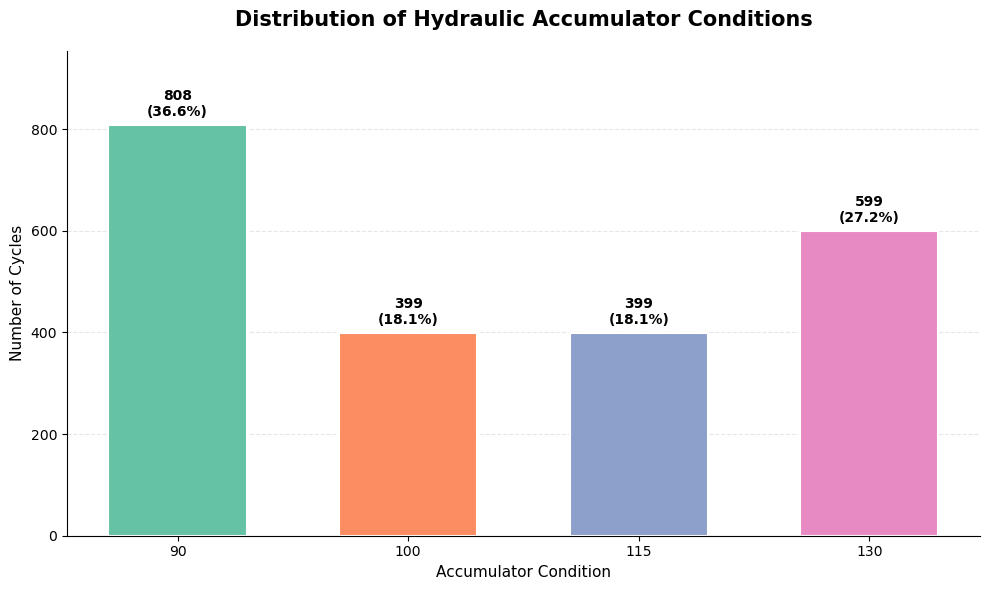

In [13]:


# Visualize the distribution of accumulator conditions

class_counts = df["Accumulator_Condition"].value_counts().sort_index()
class_percentages = (class_counts / class_counts.sum()) * 100

plt.figure(figsize=(10, 6))

colors = sns.color_palette("Set2", len(class_counts))

bars = plt.bar(
    class_counts.index.astype(str),
    class_counts.values,
    color=colors,
    width=0.6,
    edgecolor="white",
    linewidth=1.5
)

# Add count and percentage labels

for bar, count, percentage in zip(
    bars, class_counts.values, class_percentages.values
):
    plt.text(
        bar.get_x() + bar.get_width() / 2,
        bar.get_height() + 12,
        f"{count}\n({percentage:.1f}%)",
        ha="center",
        va="bottom",
        fontsize=10,
        fontweight="bold"
    )

plt.title(
    "Distribution of Hydraulic Accumulator Conditions",
    fontsize=15,
    fontweight="bold",
    pad=18
)

plt.xlabel("Accumulator Condition", fontsize=11)
plt.ylabel("Number of Cycles", fontsize=11)

plt.ylim(0, max(class_counts.values) * 1.18)

plt.grid(axis="y", linestyle="--", alpha=0.3)
plt.gca().set_axisbelow(True)

sns.despine()

plt.tight_layout()
plt.show()



### 4.2 Target Distribution — Observations

The dataset contains 2,205 hydraulic cycles distributed across four accumulator condition classes.

- Condition 90 contains 808 cycles (36.64%).
- Condition 100 contains 399 cycles (18.10%).
- Condition 115 contains 399 cycles (18.10%).
- Condition 130 contains 599 cycles (27.17%).

Condition 90 is the most represented class, while conditions 100 and 115 have the fewest observations.

The class distribution is not uniform. Therefore, model evaluation will consider per-class performance and macro-averaged F1-score in addition to overall accuracy.

No resampling will be applied unless later model results provide a clear reason to investigate it.



## 5. Sensor Feature Analysis

The dataset contains 84 statistical features extracted from 14 physical sensor signals. Each signal is summarized using its mean, standard deviation, minimum, maximum, range, and root mean square (RMS).

Before developing machine learning models, we examine feature variability to identify constant or nearly constant features that may provide limited predictive information.

The feature analysis will be conducted separately from the cycle identifier and target variable.


In [14]:

# Separate sensor features from the cycle identifier and target

sensor_features = df.drop(
    columns=["Cycle", "Accumulator_Condition"]
)

print("Number of sensor features:", sensor_features.shape[1])
print("Number of observations:", sensor_features.shape[0])

sensor_features.head()


Number of sensor features: 84
Number of observations: 2205


,PS1_mean,PS1_std,PS1_min,PS1_max,PS1_range,PS1_rms,PS2_mean,PS2_std,PS2_min,PS2_max,...,TS4_min,TS4_max,TS4_range,TS4_rms,VS1_mean,VS1_std,VS1_min,VS1_max,VS1_range,VS1_rms
0,160.67350,13.938147,145.83,191.51,45.679993,161.27692,109.466920,47.110580,0.0,156.99,...,30.363,33.594,3.231001,31.764551,0.576950,0.026852,0.532,0.624,0.092,0.577574
1,160.60332,14.117792,145.73,191.47,45.740005,161.22264,109.354900,47.041687,0.0,157.56,...,33.648,35.148,1.500000,34.496567,0.565850,0.027013,0.524,0.626,0.102,0.566494
2,160.34772,14.191435,145.37,191.41,46.040010,160.97450,109.158850,46.988144,0.0,156.97,...,35.098,36.141,1.042999,35.647343,0.576533,0.036422,0.529,0.662,0.133,0.577683
3,160.18808,14.226617,145.14,191.34,46.199997,160.81860,109.064810,46.968304,0.0,156.44,...,36.105,36.988,0.882999,36.580390,0.569267,0.033184,0.527,0.645,0.118,0.570233
4,160.00047,14.275245,144.95,191.41,46.460007,160.63603,108.931435,46.871037,0.0,158.13,...,36.992,37.781,0.788998,37.428654,0.577367,0.033203,0.524,0.660,0.136,0.578321



### 5.1 Constant Feature Analysis

A constant feature has the same value across all observations and therefore cannot distinguish between accumulator conditions.

We count the unique values in each sensor feature to identify columns with no variation. These features will be reviewed before any removal decision is made.


In [15]:
# Identify features with only one unique value

constant_features = sensor_features.columns[
    sensor_features.nunique(dropna=False) == 1
]

print("Number of constant features:", len(constant_features))
print("Constant features:", constant_features.tolist())

Number of constant features: 2
Constant features: ['PS2_min', 'PS3_min']



### 5.2 Feature Variance Analysis

Variance measures how much a feature varies across observations. A feature with zero variance is constant, while a very small variance may indicate limited variation.

Variance is affected by measurement scale, so low variance alone is not sufficient evidence that a feature is unimportant. We will use these results as an initial screening step rather than automatically deleting features.


In [16]:

# Calculate the variance of each sensor feature

feature_variance = sensor_features.var().sort_values()

# Display the 15 features with the lowest variance
print("15 features with the lowest variance:")

display(
    feature_variance.head(15).to_frame(name="Variance")
)


15 features with the lowest variance:


,Variance
PS2_min,0.000000e+00
PS3_min,0.000000e+00
FS1_min,4.535147e-10
PS5_std,4.388111e-06
PS6_std,4.425430e-06
FS2_std,1.613609e-05
PS5_range,1.166376e-04
PS6_range,1.249331e-04
TS3_std,4.463999e-04
FS2_range,4.501682e-04



### 5.3 Verification of Constant Features

Features with zero variance are examined to confirm that they contain only one unique value across all observations.

Such features cannot distinguish between accumulator conditions based on their values. We will verify the results before excluding them from the model's input features.


In [17]:
# Verify the unique values of constant features

for feature in constant_features:
    print(f"\nFeature: {feature}")
    print("Unique values:", sensor_features[feature].unique())
    print("Number of unique values:", sensor_features[feature].nunique())
    print("-" * 40)


Feature: PS2_min
Unique values: [0.]
Number of unique values: 1
----------------------------------------

Feature: PS3_min
Unique values: [0.]
Number of unique values: 1
----------------------------------------



### 5.4 Investigation of Low-Variance Features

Features with very low variance are examined further to understand their range and number of unique values.

Low variance alone is not sufficient justification for removing a feature, particularly when sensor features may have different physical units.


In [18]:

# Examine the feature with the lowest non-zero variance

feature = "FS1_min"

print("Feature:", feature)
print("Unique values:", sensor_features[feature].nunique())
print("Minimum:", sensor_features[feature].min())
print("Maximum:", sensor_features[feature].max())
print("Mean:", sensor_features[feature].mean())
print("Standard deviation:", sensor_features[feature].std())

display(sensor_features[feature].describe().to_frame())


Feature: FS1_min
Unique values: 2
Minimum: 0.0
Maximum: 0.001
Mean: 4.53514739229025e-07
Standard deviation: 2.1295885499997694e-05


,FS1_min
count,2.205000e+03
mean,4.535147e-07
std,2.129589e-05
min,0.000000e+00
25%,0.000000e+00
50%,0.000000e+00
75%,0.000000e+00
max,1.000000e-03



### 5.5 Removal of Constant Features

Constant features contain the same value across all observations and cannot distinguish between accumulator conditions. After verifying these features, we exclude them from the sensor feature set used in subsequent analysis.

In [19]:
# Remove the verified constant features from the sensor feature set

zero_var_cols = constant_features.tolist()

sensor_features_clean = sensor_features.drop(
    columns=zero_var_cols
)

print("Constant features removed:", zero_var_cols)
print("Features before removal:", sensor_features.shape[1])
print("Features after removal:", sensor_features_clean.shape[1])

Constant features removed: ['PS2_min', 'PS3_min']
Features before removal: 84
Features after removal: 82


### 5.6 Feature Variability — Initial Findings

The initial feature analysis identified two constant sensor features, `PS2_min` and `PS3_min`. Their values were verified to be constant across all observations, so they were excluded from the sensor feature set.

The remaining sensor features were retained for further exploratory analysis. In particular, `FS1_min` was investigated separately because of its very low variance. A small variance alone does not establish that a feature is uninformative, especially when sensor measurements use different physical units.

Further feature screening will consider correlation, redundancy, and the relationship between sensor measurements and the target condition before any additional features are removed.


## 6. Feature Correlation Analysis

Correlation analysis is used to identify relationships between sensor-derived features and detect potentially redundant information.

Since each physical sensor has six statistical features, some features may contain similar information. For example, the mean and RMS values of a sensor may be strongly correlated.

Identifying highly correlated features helps us understand the relationships within the dataset and assess potential multicollinearity before model development.

No features will be removed solely based on correlation. Further decisions will consider their relevance to accumulator condition prediction and model performance.

### 6.1 Calculate the correlation matrix

In [20]:
# Calculate correlations between sensor features

correlation_matrix = sensor_features_clean.corr()

print("Correlation matrix shape:", correlation_matrix.shape)

display(correlation_matrix.head())

Correlation matrix shape: (82, 82)


,PS1_mean,PS1_std,PS1_min,PS1_max,PS1_range,PS1_rms,PS2_mean,PS2_std,PS2_max,PS2_range,...,TS4_min,TS4_max,TS4_range,TS4_rms,VS1_mean,VS1_std,VS1_min,VS1_max,VS1_range,VS1_rms
PS1_mean,1.000000,0.827146,-0.148644,-0.300222,0.089063,0.999707,0.995294,0.980692,-0.098517,-0.098517,...,0.171674,0.170397,-0.020228,0.171000,0.442242,-0.065551,0.342008,-0.008797,-0.113130,0.418567
PS1_std,0.827146,1.000000,-0.625422,-0.727462,0.572501,0.840497,0.861751,0.916661,-0.369448,-0.369448,...,0.643492,0.642151,0.099981,0.642824,0.803520,0.248181,0.722906,0.358826,0.190525,0.784137
PS1_min,-0.148644,-0.625422,1.000000,0.951472,-0.993526,-0.169869,-0.222543,-0.317560,0.581305,0.581305,...,-0.978963,-0.978978,-0.257021,-0.979039,-0.907248,-0.557032,-0.898142,-0.702506,-0.528928,-0.902485
PS1_max,-0.300222,-0.727462,0.951472,1.000000,-0.910354,-0.320446,-0.367700,-0.464021,0.588407,0.588407,...,-0.939584,-0.939234,-0.228077,-0.939483,-0.913939,-0.503171,-0.892226,-0.642646,-0.462568,-0.906240
PS1_range,0.089063,0.572501,-0.993526,-0.910354,1.000000,0.110140,0.163530,0.255748,-0.564506,-0.564506,...,0.969625,0.969775,0.261437,0.969765,0.882652,0.563330,0.878423,0.707471,0.540525,0.879089


### 6.2 Identification of Highly Correlated Features

Highly correlated feature pairs are examined to identify sensor measurements that may provide overlapping information.

A correlation threshold of 0.95 is used as an initial screening criterion. This threshold helps highlight strong linear relationships but does not automatically determine which features should be removed.

In [21]:
# Identify highly correlated feature pairs

import numpy as np

upper_triangle = correlation_matrix.where(
    np.triu(np.ones(correlation_matrix.shape), k=1).astype(bool)
)

high_corr_pairs = (
    upper_triangle.stack()
    .reset_index()
)

high_corr_pairs.columns = [
    "Feature 1", "Feature 2", "Correlation"
]

high_corr_pairs = high_corr_pairs[
    high_corr_pairs["Correlation"].abs() >= 0.95
]

high_corr_pairs["Absolute Correlation"] = (
    high_corr_pairs["Correlation"].abs()
)

high_corr_pairs = high_corr_pairs.sort_values(
    by="Absolute Correlation",
    ascending=False
)

print("Number of highly correlated pairs:", len(high_corr_pairs))

display(high_corr_pairs)

Number of highly correlated pairs: 539


,Feature 1,Feature 2,Correlation,Absolute Correlation
620,PS2_max,PS2_range,1.000000,1.000000
975,PS3_max,PS3_range,1.000000,1.000000
3172,TS3_mean,TS3_rms,1.000000,1.000000
3049,TS2_mean,TS2_rms,1.000000,1.000000
1555,PS5_mean,PS5_rms,1.000000,1.000000
...,...,...,...,...
1737,PS5_max,EPS1_range,-0.954676,0.954676
2052,PS6_max,EPS1_range,-0.954525,0.954525
1369,PS4_max,PS4_rms,0.952003,0.952003
361,PS1_range,FS2_min,-0.951672,0.951672


### 6.2.1 Interpretation of Highly Correlated Features

The correlation analysis identified 539 feature pairs with an absolute Pearson correlation coefficient of 0.95 or higher.

This indicates strong linear relationships between several sensor-derived features. Such relationships may arise because multiple statistical measurements are calculated from the same physical sensor signal.

Highly correlated features may contain overlapping information and can introduce multicollinearity, particularly in linear models such as Logistic Regression.

However, high correlation does not automatically make a feature irrelevant. Therefore, the identified pairs will be examined further before making any feature-selection decisions.

In [22]:
# Display the 20 strongest correlated feature pairs

display(
    high_corr_pairs
    .sort_values(
        by="Absolute Correlation",
        ascending=False
    )
    .head(20)
)

,Feature 1,Feature 2,Correlation,Absolute Correlation
620,PS2_max,PS2_range,1.000000,1.000000
975,PS3_max,PS3_range,1.000000,1.000000
3172,TS3_mean,TS3_rms,1.000000,1.000000
3049,TS2_mean,TS2_rms,1.000000,1.000000
1555,PS5_mean,PS5_rms,1.000000,1.000000
1894,PS6_mean,PS6_rms,1.000000,1.000000
2695,FS2_mean,FS2_rms,1.000000,1.000000
2890,TS1_mean,TS1_rms,1.000000,1.000000
2580,FS1_max,FS1_range,1.000000,1.000000
3259,TS4_mean,TS4_rms,1.000000,1.000000


In [23]:
# Count highly correlated feature pairs by correlation direction

positive_pairs = (
    high_corr_pairs["Correlation"] >= 0.95
).sum()

negative_pairs = (
    high_corr_pairs["Correlation"] <= -0.95
).sum()

print("Strong positive correlations:", positive_pairs)
print("Strong negative correlations:", negative_pairs)
print("Total highly correlated pairs:", len(high_corr_pairs))

Strong positive correlations: 271
Strong negative correlations: 268
Total highly correlated pairs: 539


### 6.2.2 Verification of Redundant Features

Highly correlated features are examined to determine whether they contain identical values or represent different measurements with a strong linear relationship.

This verification helps distinguish exact duplicate features from highly correlated features that may still provide different information.

In [24]:
# Examine the strongest correlated feature pairs

top_pairs = high_corr_pairs.sort_values(
    by="Absolute Correlation",
    ascending=False
).head(10)

for _, row in top_pairs.iterrows():

    feature1 = row["Feature 1"]
    feature2 = row["Feature 2"]

    difference = (
        sensor_features_clean[feature1] -
        sensor_features_clean[feature2]
    ).abs()

    print(f"\n{feature1} vs {feature2}")
    print("Identical values:",
          sensor_features_clean[feature1].equals(
              sensor_features_clean[feature2]
          ))
    print("Maximum absolute difference:", difference.max())


PS2_max vs PS2_range
Identical values: True
Maximum absolute difference: 0.0

PS3_max vs PS3_range
Identical values: True
Maximum absolute difference: 0.0

TS3_mean vs TS3_rms
Identical values: False
Maximum absolute difference: 0.001125000000001819

TS2_mean vs TS2_rms
Identical values: False
Maximum absolute difference: 0.0017970000000033792

PS5_mean vs PS5_rms
Identical values: False
Maximum absolute difference: 0.00039499999999925706

PS6_mean vs PS6_rms
Identical values: False
Maximum absolute difference: 0.0003740000000007626

FS2_mean vs FS2_rms
Identical values: False
Maximum absolute difference: 0.0004089999999994376

TS1_mean vs TS1_rms
Identical values: False
Maximum absolute difference: 0.004595000000001903

FS1_max vs FS1_range
Identical values: False
Maximum absolute difference: 0.0010000000000012221

TS4_mean vs TS4_rms
Identical values: False
Maximum absolute difference: 0.02660299999999438


In [25]:
exact_duplicate_pairs = []

for _, row in high_corr_pairs.iterrows():
    feature1 = row["Feature 1"]
    feature2 = row["Feature 2"]

    if sensor_features_clean[feature1].equals(
        sensor_features_clean[feature2]
    ):
        exact_duplicate_pairs.append((feature1, feature2))

print("Number of identical feature pairs:",
      len(exact_duplicate_pairs))

print("\nIdentical feature pairs:")
for pair in exact_duplicate_pairs:
    print(pair)

Number of identical feature pairs: 2

Identical feature pairs:
('PS2_max', 'PS2_range')
('PS3_max', 'PS3_range')


### 6.3 Correlation Heatmap of Sensor Features

A correlation heatmap is used to visualize relationships between sensor-derived features.

Since the dataset contains numerous features, the visualization focuses on selected sensor measurements to improve readability. The complete correlation matrix is retained for further analysis.

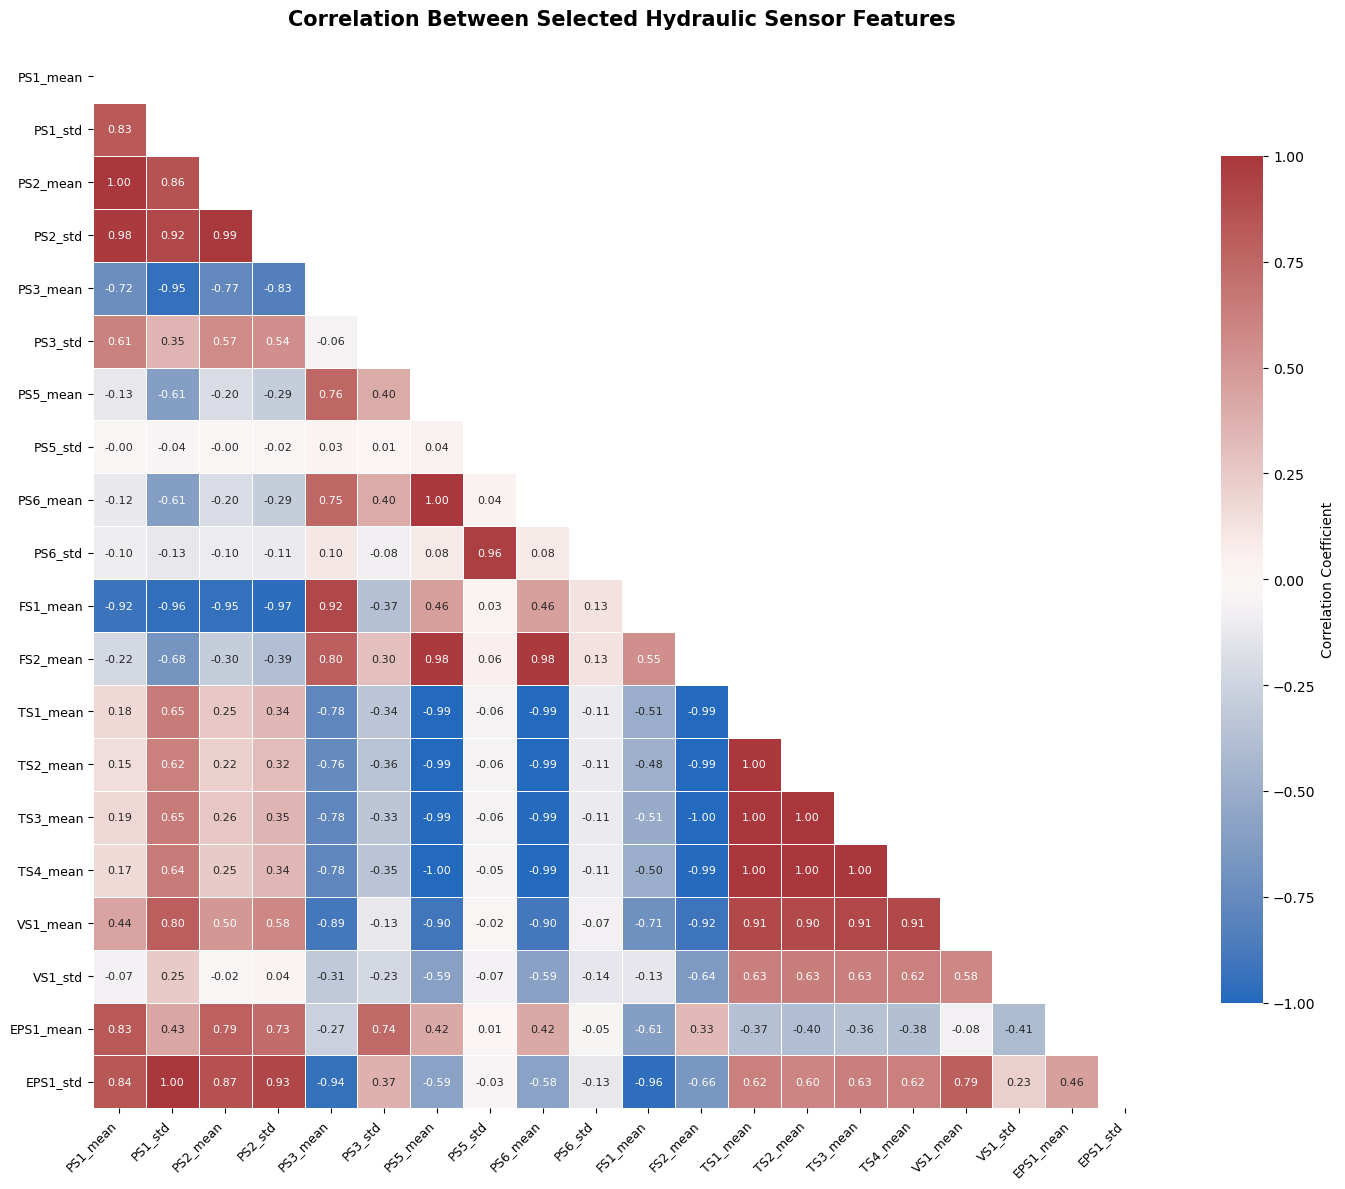

In [26]:
# Select representative features from different sensors

selected_features = [
    "PS1_mean", "PS1_std",
    "PS2_mean", "PS2_std",
    "PS3_mean", "PS3_std",
    "PS5_mean", "PS5_std",
    "PS6_mean", "PS6_std",
    "FS1_mean", "FS2_mean",
    "TS1_mean", "TS2_mean",
    "TS3_mean", "TS4_mean",
    "VS1_mean", "VS1_std",
    "EPS1_mean", "EPS1_std"
]

# Calculate correlation for selected features

selected_correlation = sensor_features_clean[
    selected_features
].corr()


# Plot an improved correlation heatmap

mask = np.triu(
    np.ones_like(selected_correlation, dtype=bool)
)

plt.figure(figsize=(15, 12))

sns.heatmap(
    selected_correlation,
    mask=mask,
    annot=True,
    fmt=".2f",
    cmap="vlag",
    center=0,
    vmin=-1,
    vmax=1,
    linewidths=0.5,
    linecolor="white",
    square=True,
    annot_kws={"size": 8},
    cbar_kws={
        "shrink": 0.8,
        "label": "Correlation Coefficient"
    }
)

plt.title(
    "Correlation Between Selected Hydraulic Sensor Features",
    fontsize=15,
    fontweight="bold",
    pad=18
)

plt.xticks(rotation=45, ha="right", fontsize=9)
plt.yticks(rotation=0, fontsize=9)

plt.tight_layout()
plt.show()


### 6.3.1 Interpretation of the Correlation Heatmap

The heatmap shows strong positive and negative linear relationships among several sensor-derived features. Some features, particularly pressure, flow, and temperature measurements, exhibit very high correlations, suggesting that they may contain overlapping information.

These relationships may lead to multicollinearity in certain machine learning algorithms, particularly linear models. However, correlation alone is not sufficient reason to remove a feature. Further verification is required to distinguish identical features from strongly correlated but different measurements.

The heatmap represents selected sensor features for visualization, while the complete correlation analysis was performed using all 82 remaining sensor features.

### 6.4 Removal of Exact Duplicate Features

The verification identified two pairs of features with identical values across all observations: `PS2_max` and `PS2_range`, and `PS3_max` and `PS3_range`.

These duplicates occur because the corresponding minimum pressure measurements (`PS2_min` and `PS3_min`) are constant at zero. Consequently, their range values are identical to their maximum values.

To avoid redundant information, `PS2_range` and `PS3_range` are removed, while the maximum-pressure features are retained. Other highly correlated features are preserved because their values are not identical.

In [27]:
# Remove only the two confirmed duplicate features

duplicate_features_to_remove = [
    "PS2_range",
    "PS3_range"
]

sensor_features_selected = sensor_features_clean.drop(
    columns=duplicate_features_to_remove
)

print("Duplicate features removed:", duplicate_features_to_remove)
print("Features before removal:", sensor_features_clean.shape[1])
print("Features after removal:", sensor_features_selected.shape[1])

Duplicate features removed: ['PS2_range', 'PS3_range']
Features before removal: 82
Features after removal: 80


## 7. Preparing Data for Machine Learning

### 7.1 Separating Input Features and Target Variable

The dataset is divided into input features (X) and the target variable (y).

The initial input features contain 84 physical sensor measurements. The `Cycle` column is excluded because it is an identifier rather than a physical sensor measurement.

The target variable, `Accumulator_Condition`, represents the hydraulic accumulator's operating condition.

Feature filtering will be performed after the chronological train-test split. This ensures that decisions about constant and duplicate features are based only on the training data, preventing the final test set from influencing preprocessing decisions.

In [28]:
# Separate input features and target variable

X = sensor_features.copy()

y = df.loc[X.index, "Accumulator_Condition"].astype(int)

print("Initial input features:", X.shape)
print("Target variable:", y.shape)

print("\nCycle column included in X:", "Cycle" in X.columns)
print("Target variable:", y.name)

display(X.head())

Initial input features: (2205, 84)
Target variable: (2205,)

Cycle column included in X: False
Target variable: Accumulator_Condition


,PS1_mean,PS1_std,PS1_min,PS1_max,PS1_range,PS1_rms,PS2_mean,PS2_std,PS2_min,PS2_max,...,TS4_min,TS4_max,TS4_range,TS4_rms,VS1_mean,VS1_std,VS1_min,VS1_max,VS1_range,VS1_rms
0,160.67350,13.938147,145.83,191.51,45.679993,161.27692,109.466920,47.110580,0.0,156.99,...,30.363,33.594,3.231001,31.764551,0.576950,0.026852,0.532,0.624,0.092,0.577574
1,160.60332,14.117792,145.73,191.47,45.740005,161.22264,109.354900,47.041687,0.0,157.56,...,33.648,35.148,1.500000,34.496567,0.565850,0.027013,0.524,0.626,0.102,0.566494
2,160.34772,14.191435,145.37,191.41,46.040010,160.97450,109.158850,46.988144,0.0,156.97,...,35.098,36.141,1.042999,35.647343,0.576533,0.036422,0.529,0.662,0.133,0.577683
3,160.18808,14.226617,145.14,191.34,46.199997,160.81860,109.064810,46.968304,0.0,156.44,...,36.105,36.988,0.882999,36.580390,0.569267,0.033184,0.527,0.645,0.118,0.570233
4,160.00047,14.275245,144.95,191.41,46.460007,160.63603,108.931435,46.871037,0.0,158.13,...,36.992,37.781,0.788998,37.428654,0.577367,0.033203,0.524,0.660,0.136,0.578321


### 7.2 Target Class Distribution

Examining the target distribution helps identify whether the dataset is balanced or imbalanced. This is important because a model trained on an imbalanced dataset may perform better on majority classes while struggling to identify minority classes.

,Number of Observations,Percentage (%)
Accumulator_Condition,,
90,808,36.643991
100,399,18.095238
115,399,18.095238
130,599,27.165533


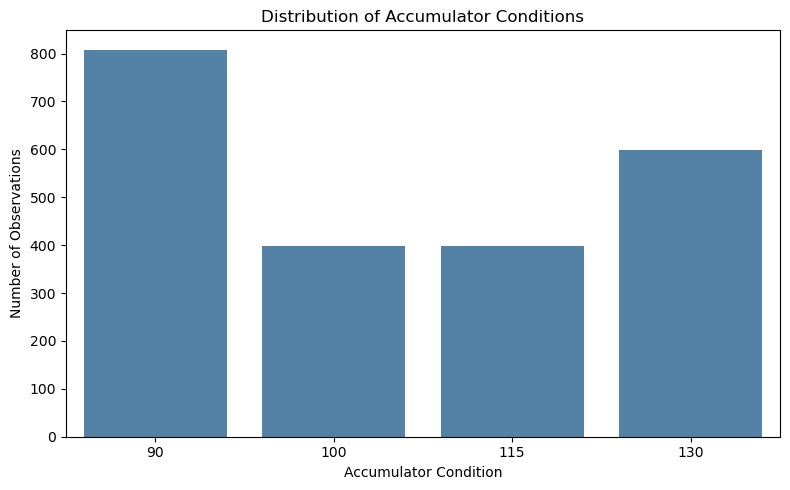

In [29]:
# Calculate target class distribution

class_counts = y.value_counts().sort_index()
class_percentages = (y.value_counts(normalize=True) * 100).sort_index()

class_distribution = pd.DataFrame({
    "Number of Observations": class_counts,
    "Percentage (%)": class_percentages
})

display(class_distribution)

# Visualize target distribution

plt.figure(figsize=(8, 5))
sns.countplot(
    x=y,
    order=sorted(y.unique()),
    color="steelblue"
)

plt.title("Distribution of Accumulator Conditions")
plt.xlabel("Accumulator Condition")
plt.ylabel("Number of Observations")
plt.tight_layout()
plt.show()

### 7.3 Check cycle order

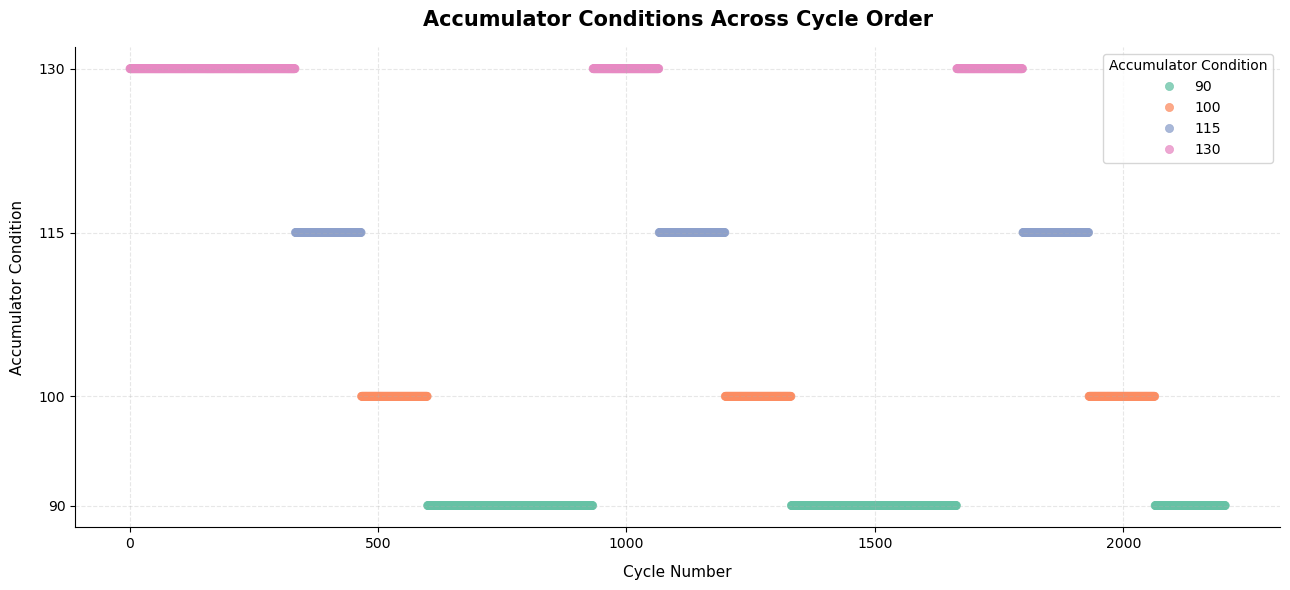

In [30]:
# Examine accumulator conditions across cycle order

plt.figure(figsize=(13, 6))

sns.scatterplot(
    x=df.loc[X.index, "Cycle"],
    y=y,
    hue=y,
    palette="Set2",
    s=35,
    alpha=0.75,
    edgecolor=None
)

plt.title(
    "Accumulator Conditions Across Cycle Order",
    fontsize=15,
    fontweight="bold",
    pad=15
)

plt.xlabel("Cycle Number", fontsize=11, labelpad=10)
plt.ylabel("Accumulator Condition", fontsize=11, labelpad=10)

plt.yticks(sorted(y.unique()))
plt.xticks(fontsize=10)
plt.yticks(fontsize=10)

plt.legend(title="Accumulator Condition")
plt.grid(axis="both", linestyle="--", alpha=0.3)
sns.despine()

plt.tight_layout()
plt.show()

### 7.4 Identifying Consecutive Condition Blocks

The cycle-order plot suggests that accumulator conditions occur in consecutive groups. We examine these groups to understand how the condition labels change across the dataset.

This helps us choose a train-test splitting strategy that reduces the risk of placing neighbouring cycles from the same condition block in both training and testing sets.

In [31]:
# Identify consecutive blocks of accumulator conditions

cycle_data = pd.DataFrame({
    "Cycle": df.loc[X.index, "Cycle"],
    "Condition": y
}).reset_index(drop=True)

# Assign a new group whenever the condition changes
cycle_data["Block"] = (
    cycle_data["Condition"] != cycle_data["Condition"].shift()
).cumsum()

# Summarize each consecutive block
condition_blocks = cycle_data.groupby("Block").agg(
    Condition=("Condition", "first"),
    Start_Cycle=("Cycle", "first"),
    End_Cycle=("Cycle", "last"),
    Number_of_Cycles=("Condition", "size")
).reset_index(drop=True)

display(condition_blocks)

print("Total number of consecutive condition blocks:",
      len(condition_blocks))

,Condition,Start_Cycle,End_Cycle,Number_of_Cycles
0,130,1,333,333
1,115,334,466,133
2,100,467,599,133
3,90,600,932,333
4,130,933,1065,133
5,115,1066,1198,133
6,100,1199,1331,133
7,90,1332,1664,333
8,130,1665,1797,133
9,115,1798,1930,133


Total number of consecutive condition blocks: 12


### 7.5 Chronological Train-Test Split

The cycle-order analysis revealed three repeated sequences of accumulator conditions. To reduce the risk of information leakage between neighbouring cycles, a chronological holdout strategy is used.

The first two sequences (cycles 1–1664) are used for training, while the final sequence (cycles 1665–2205) is reserved for testing.

This allows the model to be evaluated on a later sequence that was not used during training.

In [32]:
# Chronological train-test split

cycle_numbers = df.loc[X.index, "Cycle"]

train_mask = cycle_numbers <= 1664
test_mask = cycle_numbers > 1664

# Split the original features before performing feature filtering

X_train = X.loc[train_mask].copy()
X_test = X.loc[test_mask].copy()

y_train = y.loc[train_mask].copy()
y_test = y.loc[test_mask].copy()

print("Initial training features:", X_train.shape)
print("Initial testing features:", X_test.shape)


# Step 1: Identify constant features using training data only

constant_features_train = X_train.columns[
    X_train.nunique(dropna=False) <= 1
].tolist()

print("\nConstant features identified in training data:")
print(constant_features_train)


# Step 2: Remove constant features from both datasets

X_train = X_train.drop(columns=constant_features_train)
X_test = X_test.drop(columns=constant_features_train)


# Step 3: Identify exact duplicate features using training data only

duplicate_features_train = X_train.columns[
    X_train.T.duplicated()
].tolist()

print("Duplicate features identified:", duplicate_features_train)

# Step 4: Remove duplicate features from both datasets

X_train = X_train.drop(columns=duplicate_features_train)
X_test = X_test.drop(columns=duplicate_features_train)

print("\nTraining data after duplicate removal:", X_train.shape)
print("Testing data after duplicate removal:", X_test.shape)


# Display final dataset dimensions

print("\nFinal training features:", X_train.shape)
print("Final testing features:", X_test.shape)

print("\nTraining target distribution:")
print(y_train.value_counts().sort_index())

print("\nTesting target distribution:")
print(y_test.value_counts().sort_index())

print("\nTraining cycle range:",
      cycle_numbers.loc[train_mask].min(),
      "to",
      cycle_numbers.loc[train_mask].max())

print("Testing cycle range:",
      cycle_numbers.loc[test_mask].min(),
      "to",
      cycle_numbers.loc[test_mask].max())

Initial training features: (1664, 84)
Initial testing features: (541, 84)

Constant features identified in training data:
['PS2_min', 'PS3_min']
Duplicate features identified: ['PS2_range', 'PS3_range']

Training data after duplicate removal: (1664, 80)
Testing data after duplicate removal: (541, 80)

Final training features: (1664, 80)
Final testing features: (541, 80)

Training target distribution:
Accumulator_Condition
90     666
100    266
115    266
130    466
Name: count, dtype: int64

Testing target distribution:
Accumulator_Condition
90     142
100    133
115    133
130    133
Name: count, dtype: int64

Training cycle range: 1 to 1664
Testing cycle range: 1665 to 2205


### 7.6 Feature-to-Target Analysis

After preparing the training and testing datasets, feature-to-target analysis is performed to investigate the relationship between individual sensor features and the accumulator condition.

The objective is to identify which sensor measurements provide useful information for distinguishing the four accumulator conditions.

Three statistical methods are used:

1. **ANOVA F-value:** Evaluates whether the mean values of a feature differ across the accumulator condition classes.
2. **Mutual Information:** Measures how much information a feature provides about the target, including certain nonlinear relationships.
3. **Spearman Rank Correlation:** Measures the strength and direction of a monotonic relationship between a feature and the ordered accumulator condition.

These methods provide complementary perspectives on feature relevance. The analysis uses only the training data to avoid using the final test sequence when investigating feature-target relationships.

The results will help identify potentially informative sensor measurements and guide subsequent model development.

In [33]:

# Feature-to-Target Analysis

from sklearn.feature_selection import f_classif, mutual_info_classif
from scipy.stats import spearmanr

# Identify features that have variation in the training data
variable_features = X_train.columns[
    X_train.nunique() > 1
]

X_train_analysis = X_train[variable_features]

# 1. ANOVA F-value
anova_scores, anova_pvalues = f_classif(
    X_train_analysis,
    y_train
)

# 2. Mutual Information
mi_scores = mutual_info_classif(
    X_train_analysis,
    y_train,
    random_state=42
)

# 3. Spearman Rank Correlation
spearman_scores = []

for feature in X_train_analysis.columns:
    correlation, p_value = spearmanr(
        X_train_analysis[feature],
        y_train
    )
    spearman_scores.append(correlation)

# Combine all results into one DataFrame
feature_target_results = pd.DataFrame({
    "Feature": X_train_analysis.columns,
    "ANOVA_F_Score": anova_scores,
    "ANOVA_P_Value": anova_pvalues,
    "Mutual_Information": mi_scores,
    "Spearman_Correlation": spearman_scores
})

# Calculate absolute Spearman correlation
feature_target_results["Absolute_Spearman"] = (
    feature_target_results["Spearman_Correlation"].abs()
)

# Create individual feature rankings
feature_target_results["ANOVA_Rank"] = (
    feature_target_results["ANOVA_F_Score"]
    .rank(ascending=False)
)

feature_target_results["MI_Rank"] = (
    feature_target_results["Mutual_Information"]
    .rank(ascending=False)
)

feature_target_results["Spearman_Rank"] = (
    feature_target_results["Absolute_Spearman"]
    .rank(ascending=False)
)

# Display the results ranked by Mutual Information
feature_target_results = feature_target_results.sort_values(
    by="Mutual_Information",
    ascending=False
)

print("Total features analysed:", len(variable_features))

print("\nTop 15 Features Based on Mutual Information:")

display(
    feature_target_results[
        [
            "Feature",
            "Mutual_Information",
            "ANOVA_F_Score",
            "Spearman_Correlation"
        ]
    ].head(15)
)


Total features analysed: 80

Top 15 Features Based on Mutual Information:


,Feature,Mutual_Information,ANOVA_F_Score,Spearman_Correlation
71,TS4_max,0.915694,112.993368,0.282001
52,TS1_min,0.912062,105.430573,0.278408
50,TS1_mean,0.906921,106.669699,0.279553
55,TS1_rms,0.906745,106.673727,0.279558
70,TS4_min,0.897403,111.699012,0.281936
68,TS4_mean,0.894774,112.451834,0.282070
73,TS4_rms,0.894277,112.452481,0.282072
62,TS3_mean,0.887449,99.623611,0.271920
67,TS3_rms,0.887058,99.623578,0.271919
53,TS1_max,0.887020,107.505757,0.280246


In [34]:

# Compare the top 15 features from all three methods

ranking_methods = {
    "ANOVA F-Score": "ANOVA_F_Score",
    "Mutual Information": "Mutual_Information",
    "Spearman Correlation": "Absolute_Spearman"
}

for method_name, score_column in ranking_methods.items():

    print("\nTop 15 Features -", method_name)

    top_features = feature_target_results.sort_values(
        by=score_column,
        ascending=False
    ).head(15)

    display(
        top_features[
            ["Feature", score_column]
        ].reset_index(drop=True)
    )


# Compare how often each sensor category appears
# in the top 15 of each method

def get_sensor_category(feature):

    if feature.startswith("PS"):
        return "Pressure"
    elif feature.startswith("TS"):
        return "Temperature"
    elif feature.startswith("FS"):
        return "Flow"
    elif feature.startswith("VS"):
        return "Vibration"
    elif feature.startswith("EPS"):
        return "Motor Power"
    else:
        return "Other"


category_results = []

for method_name, score_column in ranking_methods.items():

    top_features = feature_target_results.sort_values(
        by=score_column,
        ascending=False
    ).head(15)

    categories = top_features["Feature"].apply(
        get_sensor_category
    )

    category_counts = categories.value_counts()

    for category, count in category_counts.items():

        category_results.append({
            "Ranking Method": method_name,
            "Sensor Category": category,
            "Top 15 Count": count
        })


category_summary = pd.DataFrame(category_results)

print("\nSensor Category Representation Across Ranking Methods:")

display(
    category_summary.pivot(
        index="Sensor Category",
        columns="Ranking Method",
        values="Top 15 Count"
    ).fillna(0).astype(int)
)



Top 15 Features - ANOVA F-Score


,Feature,ANOVA_F_Score
0,FS1_max,272.933979
1,FS1_range,272.931517
2,PS3_max,208.917672
3,VS1_min,171.846847
4,PS1_range,148.899947
5,PS1_min,143.940505
6,PS6_min,132.893187
7,PS5_min,131.394490
8,PS6_mean,130.484727
9,PS6_rms,130.483082



Top 15 Features - Mutual Information


,Feature,Mutual_Information
0,TS4_max,0.915694
1,TS1_min,0.912062
2,TS1_mean,0.906921
3,TS1_rms,0.906745
4,TS4_min,0.897403
5,TS4_mean,0.894774
6,TS4_rms,0.894277
7,TS3_mean,0.887449
8,TS3_rms,0.887058
9,TS1_max,0.887020



Top 15 Features - Spearman Correlation


,Feature,Absolute_Spearman
0,FS1_max,0.584774
1,FS1_range,0.584774
2,PS3_max,0.564744
3,VS1_min,0.523408
4,VS1_mean,0.465739
5,VS1_rms,0.455642
6,TS1_range,0.441884
7,PS1_range,0.436728
8,TS1_std,0.434943
9,VS1_max,0.417046



Sensor Category Representation Across Ranking Methods:


Ranking Method,ANOVA F-Score,Mutual Information,Spearman Correlation
Sensor Category,,,
Flow,2,2,2
Pressure,12,0,7
Temperature,0,13,2
Vibration,1,0,4


#### 7.6.1 Key Findings from Feature-to-Target Analysis

The feature-to-target analysis revealed different patterns across the three statistical methods.

**1. ANOVA F-value findings**

Pressure and flow measurements were prominent in the ANOVA ranking. Twelve of the top 15 features belonged to pressure sensors, while two belonged to flow sensors. `FS1_max` recorded the highest F-value of approximately 272.93, closely followed by `FS1_range`.

This indicates substantial differences in these feature values across the accumulator-condition classes.

**2. Mutual Information findings**

Temperature measurements dominated the Mutual Information ranking, accounting for 13 of the top 15 features. `TS4_max` achieved the highest score of approximately 0.916.

This suggests that temperature measurements contain useful information for distinguishing the accumulator conditions, including potentially nonlinear relationships.

**3. Spearman correlation findings**

Pressure and vibration measurements were prominent in the Spearman ranking. `FS1_range` and `FS1_max` recorded the highest absolute correlation of approximately 0.585, followed by `PS3_max` at approximately 0.565.

This indicates relatively strong monotonic associations between these measurements and the ordered accumulator-condition labels.

**Overall interpretation**

The three methods highlighted different sensor categories: ANOVA emphasised pressure and flow, Mutual Information emphasised temperature, and Spearman correlation emphasised pressure and vibration.

These results suggest that accumulator-condition information is distributed across multiple sensor categories. No single statistical ranking should be treated as a definitive measure of feature importance.

The findings represent statistical associations within the training data and do not establish causal relationships or guarantee predictive performance on unseen cycles.

In [35]:

# Identify features commonly ranked in the top 15
# by different statistical methods

anova_top = set(
    feature_target_results.nlargest(
        15, "ANOVA_F_Score"
    )["Feature"]
)

mi_top = set(
    feature_target_results.nlargest(
        15, "Mutual_Information"
    )["Feature"]
)

spearman_top = set(
    feature_target_results.nlargest(
        15, "Absolute_Spearman"
    )["Feature"]
)

print("ANOVA and Mutual Information overlap:")
print(sorted(anova_top.intersection(mi_top)))

print("\nANOVA and Spearman overlap:")
print(sorted(anova_top.intersection(spearman_top)))

print("\nMutual Information and Spearman overlap:")
print(sorted(mi_top.intersection(spearman_top)))

print("\nFeatures common to all three methods:")
print(sorted(anova_top.intersection(mi_top, spearman_top)))


ANOVA and Mutual Information overlap:
[]

ANOVA and Spearman overlap:
['FS1_max', 'FS1_range', 'PS1_min', 'PS1_range', 'PS3_max', 'VS1_min']

Mutual Information and Spearman overlap:
[]

Features common to all three methods:
[]


#### 7.6.2 Feature Ranking Overlap Analysis

The overlap between the three feature-ranking methods was examined to identify features consistently highlighted by different statistical approaches.

The comparison produced the following observations:

- ANOVA F-value and Spearman correlation shared six features: `FS1_max`, `FS1_range`, `PS1_min`, `PS1_range`, `PS3_max`, and `VS1_min`.
- No common features were found between the top 15 ANOVA and Mutual Information rankings.
- No common features were found between the top 15 Mutual Information and Spearman rankings.
- No feature appeared in all three top 15 rankings.

These findings demonstrate that the statistical methods identify different types of feature-target relationships. ANOVA and Spearman showed some agreement on pressure, flow and vibration measurements, while Mutual Information highlighted temperature measurements.

The absence of overlap does not indicate that a feature is unimportant. It reflects the different statistical properties measured by each technique.

Therefore, the rankings will be treated as exploratory evidence rather than a final feature-selection rule.

#### 7.6.3 Feature Ranking Stability Across Training Sequences

The training dataset contains two chronological operating sequences. Since sensor measurements were previously observed to change between sequences, feature-target relationships may also vary across them.

To investigate this, feature rankings will be calculated separately for Sequence 1 and Sequence 2 using ANOVA F-value and Mutual Information.

Comparing these rankings will help determine whether the most informative sensor features remain consistent across the training sequences or whether their apparent relevance changes with the operating sequence.

In [36]:

# Compare feature rankings across the two training sequences

# Identify the cycles belonging to each sequence
train_cycles = df.loc[X_train.index, "Cycle"]

sequence1_mask = train_cycles <= 932
sequence2_mask = (train_cycles >= 933) & (train_cycles <= 1664)

X_seq1 = X_train.loc[sequence1_mask]
y_seq1 = y_train.loc[sequence1_mask]

X_seq2 = X_train.loc[sequence2_mask]
y_seq2 = y_train.loc[sequence2_mask]


def calculate_feature_rankings(X_data, y_data):

    # Exclude features that are constant in this sequence
    variable_columns = X_data.columns[
        X_data.nunique() > 1
    ]

    X_analysis = X_data[variable_columns]

    # ANOVA
    anova_scores, _ = f_classif(X_analysis, y_data)

    # Mutual Information
    mi_scores = mutual_info_classif(
        X_analysis,
        y_data,
        random_state=42
    )

    rankings = pd.DataFrame({
        "Feature": variable_columns,
        "ANOVA_F_Score": anova_scores,
        "Mutual_Information": mi_scores
    })

    return rankings


# Calculate rankings separately
rankings_seq1 = calculate_feature_rankings(X_seq1, y_seq1)
rankings_seq2 = calculate_feature_rankings(X_seq2, y_seq2)


# Display top 15 features from each sequence
print("Sequence 1 - Top 15 ANOVA Features")

display(
    rankings_seq1.nlargest(15, "ANOVA_F_Score")
    [["Feature", "ANOVA_F_Score"]]
    .reset_index(drop=True)
)

print("Sequence 2 - Top 15 ANOVA Features")

display(
    rankings_seq2.nlargest(15, "ANOVA_F_Score")
    [["Feature", "ANOVA_F_Score"]]
    .reset_index(drop=True)
)

print("Sequence 1 - Top 15 Mutual Information Features")

display(
    rankings_seq1.nlargest(15, "Mutual_Information")
    [["Feature", "Mutual_Information"]]
    .reset_index(drop=True)
)

print("Sequence 2 - Top 15 Mutual Information Features")

display(
    rankings_seq2.nlargest(15, "Mutual_Information")
    [["Feature", "Mutual_Information"]]
    .reset_index(drop=True)
)


# Compare the top 15 feature overlap
for method in ["ANOVA_F_Score", "Mutual_Information"]:

    top_seq1 = set(
        rankings_seq1.nlargest(15, method)["Feature"]
    )

    top_seq2 = set(
        rankings_seq2.nlargest(15, method)["Feature"]
    )

    print(f"\n{method} - Shared top 15 features:")
    print(sorted(top_seq1.intersection(top_seq2)))

    print("Number of shared features:",
          len(top_seq1.intersection(top_seq2)))


Sequence 1 - Top 15 ANOVA Features


,Feature,ANOVA_F_Score
0,VS1_rms,168.470818
1,VS1_mean,156.439722
2,FS1_std,146.257858
3,PS1_std,144.524245
4,TS4_max,144.479163
5,TS4_rms,142.047160
6,TS4_mean,142.035690
7,EPS1_std,141.486213
8,TS4_min,139.925010
9,PS3_mean,138.745450


Sequence 2 - Top 15 ANOVA Features


,Feature,ANOVA_F_Score
0,PS1_range,322.339278
1,PS3_max,303.534315
2,PS1_min,275.418320
3,TS2_min,255.123212
4,TS1_min,254.600784
5,TS3_min,253.324620
6,TS4_min,253.024109
7,TS1_mean,252.983816
8,TS1_rms,252.979984
9,TS2_mean,252.851850


Sequence 1 - Top 15 Mutual Information Features


,Feature,Mutual_Information
0,TS4_max,0.880626
1,TS4_min,0.862029
2,TS4_mean,0.853681
3,TS4_rms,0.853456
4,TS1_min,0.842715
5,TS3_max,0.840635
6,TS3_mean,0.839793
7,TS3_rms,0.839392
8,TS3_min,0.836673
9,TS1_max,0.828306


Sequence 2 - Top 15 Mutual Information Features


,Feature,Mutual_Information
0,TS2_mean,1.067282
1,TS2_rms,1.066770
2,TS2_max,1.047560
3,TS1_mean,1.027946
4,TS1_rms,1.027925
5,TS2_min,1.021281
6,TS1_min,1.004778
7,TS1_max,0.998058
8,TS3_min,0.977640
9,TS3_max,0.977132



ANOVA_F_Score - Shared top 15 features:
['TS1_max', 'TS1_mean', 'TS1_min', 'TS1_rms', 'TS4_min']
Number of shared features: 5

Mutual_Information - Shared top 15 features:
['FS2_mean', 'FS2_rms', 'TS1_max', 'TS1_mean', 'TS1_min', 'TS1_rms', 'TS3_max', 'TS3_mean', 'TS3_min', 'TS3_rms', 'TS4_max']
Number of shared features: 11


#### 7.6.4 Key Findings from Feature Stability Analysis

Feature rankings were calculated separately for the first and second training sequences to examine whether feature-target relationships remained consistent across operating sequences.

**1. ANOVA ranking stability**

Five features appeared in the top 15 rankings of both sequences: `TS1_max`, `TS1_mean`, `TS1_min`, `TS1_rms`, and `TS4_min`.

The remaining highly ranked features differed between sequences. Sequence 1 highlighted vibration and flow measurements, whereas Sequence 2 highlighted more pressure and temperature measurements.

**2. Mutual Information ranking stability**

Eleven features appeared in the top 15 rankings of both sequences. These included temperature measurements from TS1 and TS3, temperature features from TS4, and flow measurements from FS2.

Temperature measurements were prominent in both sequences, suggesting that they consistently contain useful information about accumulator condition under the Mutual Information criterion.

**3. Overall interpretation**

Mutual Information showed greater top-15 ranking overlap across the two training sequences than ANOVA. This suggests greater consistency in the selected high-ranking features under the Mutual Information method.

However, the feature rankings were not identical, indicating that sensor-feature relationships can vary across operating sequences.

These findings support the need for sequence-aware model validation and caution against selecting features solely from a single combined ranking.

In [37]:

# Compare complete feature rankings across sequences

# Keep only features that vary in both sequences
common_features = sorted(
    set(rankings_seq1["Feature"]).intersection(
        set(rankings_seq2["Feature"])
    )
)

# Create ranking comparison table
ranking_comparison = pd.DataFrame({
    "Feature": common_features
})

# Merge ANOVA scores
ranking_comparison = ranking_comparison.merge(
    rankings_seq1[["Feature", "ANOVA_F_Score"]],
    on="Feature"
).merge(
    rankings_seq2[["Feature", "ANOVA_F_Score"]],
    on="Feature",
    suffixes=("_Seq1", "_Seq2")
)

# Merge Mutual Information scores
ranking_comparison = ranking_comparison.merge(
    rankings_seq1[["Feature", "Mutual_Information"]],
    on="Feature"
).merge(
    rankings_seq2[["Feature", "Mutual_Information"]],
    on="Feature",
    suffixes=("_Seq1", "_Seq2")
)

# Convert scores into ranks
ranking_comparison["ANOVA_Rank_Seq1"] = (
    ranking_comparison["ANOVA_F_Score_Seq1"]
    .rank(ascending=False)
)

ranking_comparison["ANOVA_Rank_Seq2"] = (
    ranking_comparison["ANOVA_F_Score_Seq2"]
    .rank(ascending=False)
)

ranking_comparison["MI_Rank_Seq1"] = (
    ranking_comparison["Mutual_Information_Seq1"]
    .rank(ascending=False)
)

ranking_comparison["MI_Rank_Seq2"] = (
    ranking_comparison["Mutual_Information_Seq2"]
    .rank(ascending=False)
)

# Calculate Spearman correlation between complete rankings
anova_rank_correlation = ranking_comparison[
    ["ANOVA_Rank_Seq1", "ANOVA_Rank_Seq2"]
].corr(method="spearman").iloc[0, 1]

mi_rank_correlation = ranking_comparison[
    ["MI_Rank_Seq1", "MI_Rank_Seq2"]
].corr(method="spearman").iloc[0, 1]

print("Number of common features:", len(common_features))

print(
    "\nANOVA ranking correlation:",
    round(anova_rank_correlation, 4)
)

print(
    "Mutual Information ranking correlation:",
    round(mi_rank_correlation, 4)
)


Number of common features: 78

ANOVA ranking correlation: 0.4928
Mutual Information ranking correlation: 0.8468


#### 7.6.5 Stability of Feature Rankings Across Training Sequences

To examine whether the relationship between sensor features and accumulator condition remains consistent across operating sequences, the feature rankings from Sequence 1 and Sequence 2 were compared using Spearman rank correlation.

**Results:**
- ANOVA ranking correlation: **0.4928**
- Mutual Information ranking correlation: **0.8468**
- Common features compared: **78**

**Key Findings:**

1. Mutual Information showed strong ranking consistency across the two sequences, suggesting that the relative importance of features in capturing information about accumulator condition was more stable under this method.
2. ANOVA showed moderate ranking consistency, indicating that differences in class-wise feature means varied more between sequences.
3. The difference between the two results suggests that the apparent relationship between sensor measurements and accumulator condition depends partly on the statistical method used.
4. These results support examining sequence variation during feature analysis rather than assuming that one ranking applies equally across all operating conditions.

**Conclusion:** Mutual Information provided more consistent feature rankings across the two training sequences than ANOVA. However, ranking consistency alone does not establish predictive performance or prove that a feature causes a particular accumulator condition.

## 8. Data Preprocessing

### 8.1 Checking Data Quality After Splitting

Before model training, the training and testing datasets are checked for missing and infinite values. This ensures that the input data are suitable for the selected machine learning algorithms.

In [38]:
# Check training and testing data quality

print("Training set")
print("Missing values:", X_train.isnull().sum().sum())
print("Infinite values:", np.isinf(X_train).sum().sum())

print("\nTesting set")
print("Missing values:", X_test.isnull().sum().sum())
print("Infinite values:", np.isinf(X_test).sum().sum())

print("\nTarget variable checks")
print("Missing training labels:", y_train.isnull().sum())
print("Missing testing labels:", y_test.isnull().sum())

Training set
Missing values: 0
Infinite values: 0

Testing set
Missing values: 0
Infinite values: 0

Target variable checks
Missing training labels: 0
Missing testing labels: 0


### 8.2 Feature Scaling

Feature scaling is used to bring numerical features onto a comparable scale. Standardization transforms features using their mean and standard deviation.

In this project, `StandardScaler` will be applied to Logistic Regression through a machine learning pipeline. The scaler is fitted on the training data and subsequently applied to the testing data using the same learned parameters, preventing data leakage.

Decision Tree and Random Forest do not require feature scaling, so their original feature values will be retained.

## 9. Model Building and Training

### 9.1 Selecting Machine Learning Models

Three supervised classification algorithms are selected for comparison: Logistic Regression, Decision Tree, and Random Forest.

A Dummy Classifier is also included as a baseline. Comparing these models helps evaluate whether more advanced algorithms learn meaningful patterns from the hydraulic sensor measurements.

In [39]:
# Divide the training data into training and validation sequences

cycle_numbers = df.loc[X_train.index, "Cycle"]

seq1_mask = cycle_numbers <= 932
seq2_mask = cycle_numbers > 932

X_seq1 = X_train.loc[seq1_mask].copy()
X_seq2 = X_train.loc[seq2_mask].copy()

y_seq1 = y_train.loc[seq1_mask].copy()
y_seq2 = y_train.loc[seq2_mask].copy()

print("Sequence 1 - Training Data:", X_seq1.shape)
print("Sequence 2 - Validation Data:", X_seq2.shape)

print("\nSequence 1 cycle range:",
      cycle_numbers.loc[seq1_mask].min(),
      "to",
      cycle_numbers.loc[seq1_mask].max())

print("Sequence 2 cycle range:",
      cycle_numbers.loc[seq2_mask].min(),
      "to",
      cycle_numbers.loc[seq2_mask].max())

Sequence 1 - Training Data: (932, 80)
Sequence 2 - Validation Data: (732, 80)

Sequence 1 cycle range: 1 to 932
Sequence 2 cycle range: 933 to 1664


In [40]:
# Import machine learning algorithms

from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.dummy import DummyClassifier

# Define the models

models = {
    "Dummy Classifier": DummyClassifier(strategy="most_frequent"),

    "Logistic Regression": Pipeline([
        ("scaler", StandardScaler()),
        ("classifier", LogisticRegression(
            max_iter=2000,
            random_state=42
        ))
    ]),

    "Decision Tree": DecisionTreeClassifier(
        random_state=42
    ),

    "Random Forest": RandomForestClassifier(
        n_estimators=300,
        random_state=42,
        n_jobs=-1
    )
}

print("Models selected for comparison:")
for model_name in models:
    print("-", model_name)

Models selected for comparison:
- Dummy Classifier
- Logistic Regression
- Decision Tree
- Random Forest


### 9.2 Evaluating Generalization Between Earlier Operating Sequences

To further investigate the effect of operating sequence changes, an additional experiment is performed.

Models are trained using the first operating sequence and evaluated using the second operating sequence. This helps assess whether the models can generalize to a different sequence before being evaluated on the final held-out sequence.

In [41]:
# Train and evaluate models between Sequence 1 and Sequence 2

sequence_results = []

for model_name, model in models.items():

    model.fit(X_seq1, y_seq1)

    y_pred = model.predict(X_seq2)

    sequence_results.append({
        "Model": model_name,
        "Accuracy": accuracy_score(y_seq2, y_pred),
        "Precision": precision_score(
            y_seq2, y_pred, average="macro", zero_division=0
        ),
        "Recall": recall_score(
            y_seq2, y_pred, average="macro", zero_division=0
        ),
        "F1 Score": f1_score(
            y_seq2, y_pred, average="macro", zero_division=0
        )
    })

sequence_results_df = pd.DataFrame(sequence_results)

display(sequence_results_df.round(4))

,Model,Accuracy,Precision,Recall,F1 Score
0,Dummy Classifier,0.4549,0.1137,0.2500,0.1563
1,Logistic Regression,0.4932,0.3682,0.3038,0.2499
2,Decision Tree,0.5014,0.2496,0.4008,0.2985
3,Random Forest,0.1380,0.0611,0.0815,0.0694


### 9.3 Examining Classification Errors Across Sequences

To understand the classification performance in greater detail, confusion matrices and classification reports are generated for the Sequence 1 to Sequence 2 experiment.

This analysis identifies which accumulator conditions are correctly classified and which conditions are frequently confused with one another.


Dummy Classifier
              precision    recall  f1-score   support

          90       0.45      1.00      0.63       333
         100       0.00      0.00      0.00       133
         115       0.00      0.00      0.00       133
         130       0.00      0.00      0.00       133

    accuracy                           0.45       732
   macro avg       0.11      0.25      0.16       732
weighted avg       0.21      0.45      0.28       732



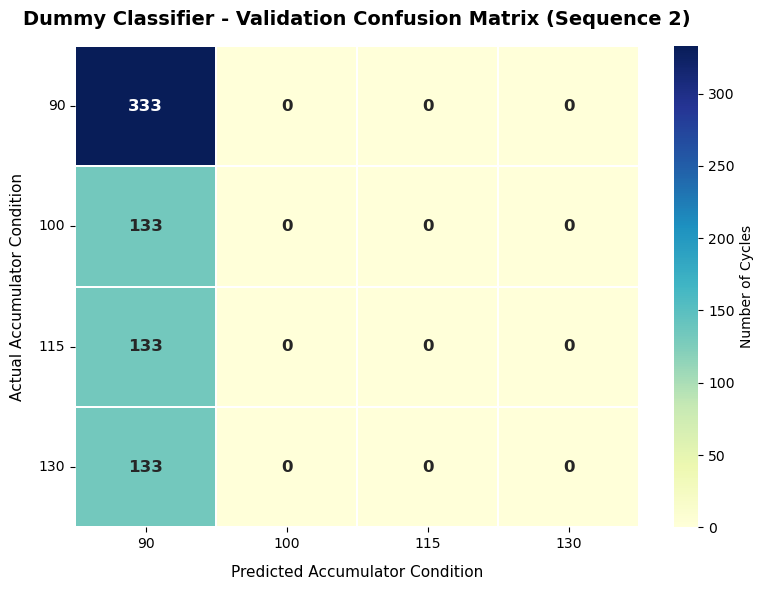


Logistic Regression
              precision    recall  f1-score   support

          90       0.47      1.00      0.64       333
         100       0.00      0.00      0.00       133
         115       0.00      0.00      0.00       133
         130       1.00      0.22      0.36       133

    accuracy                           0.49       732
   macro avg       0.37      0.30      0.25       732
weighted avg       0.40      0.49      0.36       732



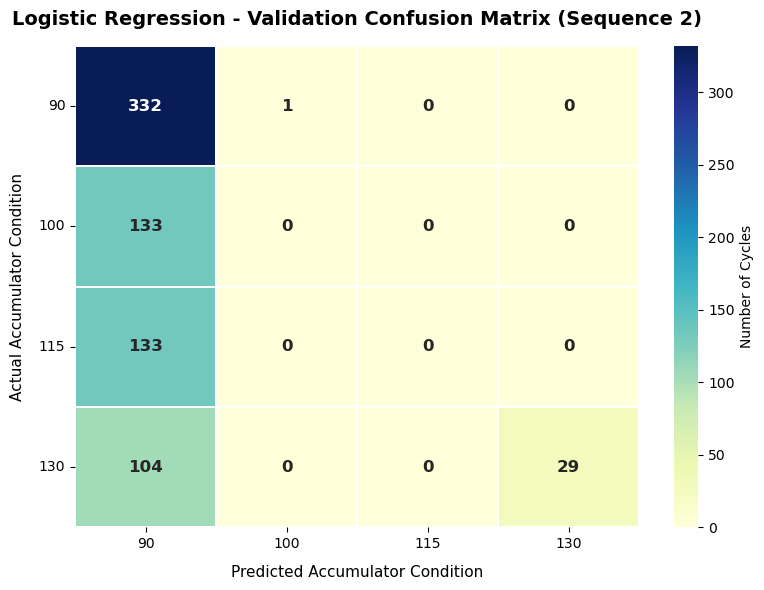


Decision Tree
              precision    recall  f1-score   support

          90       0.65      0.77      0.71       333
         100       0.00      0.00      0.00       133
         115       0.00      0.00      0.00       133
         130       0.34      0.83      0.49       133

    accuracy                           0.50       732
   macro avg       0.25      0.40      0.30       732
weighted avg       0.36      0.50      0.41       732



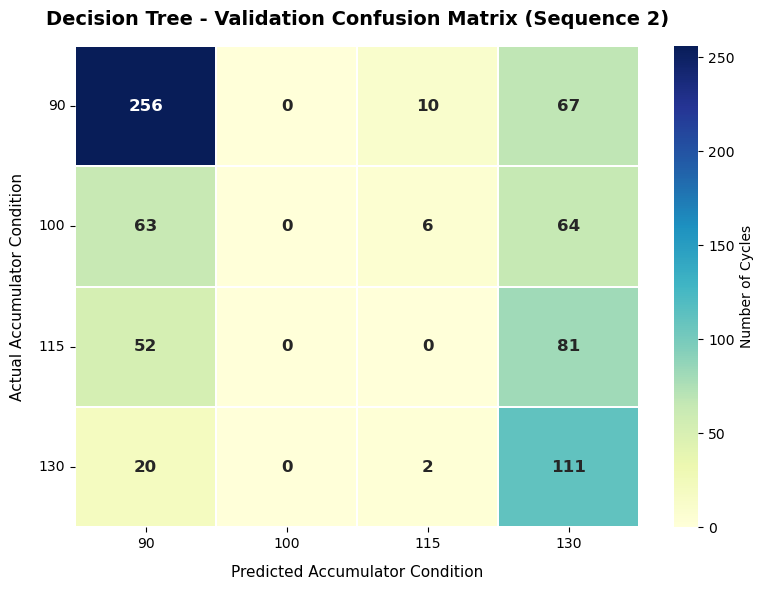


Random Forest
              precision    recall  f1-score   support

          90       0.23      0.29      0.25       333
         100       0.00      0.00      0.00       133
         115       0.00      0.00      0.00       133
         130       0.02      0.04      0.02       133

    accuracy                           0.14       732
   macro avg       0.06      0.08      0.07       732
weighted avg       0.11      0.14      0.12       732



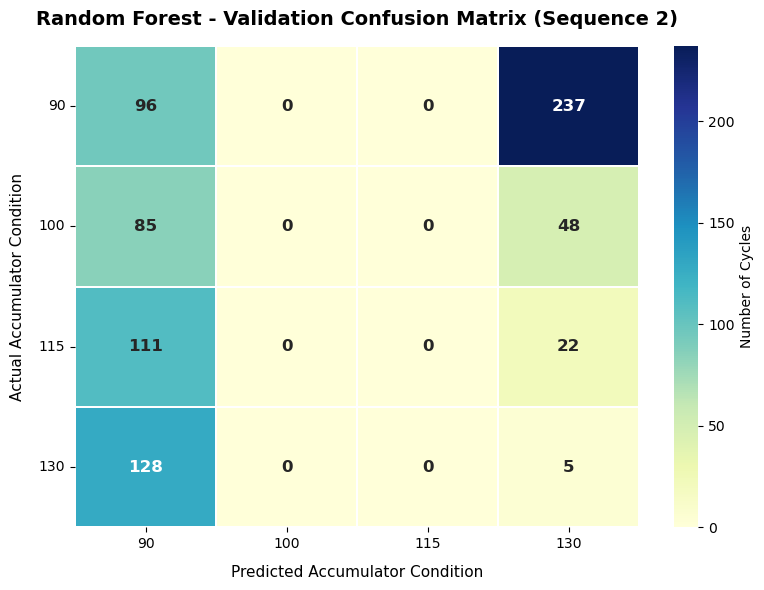

In [42]:
from sklearn.base import clone
from sklearn.metrics import confusion_matrix, classification_report
import seaborn as sns
import matplotlib.pyplot as plt

# Evaluate independent copies of the models

for model_name, original_model in models.items():

    diagnostic_model = clone(original_model)

    diagnostic_model.fit(X_seq1, y_seq1)

    y_pred_seq2 = diagnostic_model.predict(X_seq2)

    print(f"\n{model_name}")
    print(classification_report(
        y_seq2,
        y_pred_seq2,
        zero_division=0
    ))

    cm = confusion_matrix(
        y_seq2,
        y_pred_seq2,
        labels=[90, 100, 115, 130]
    )

    plt.figure(figsize=(8, 6))

    sns.heatmap(
        cm,
        annot=True,
        fmt="d",
        cmap="YlGnBu",
        linewidths=1.2,
        linecolor="white",
        xticklabels=[90, 100, 115, 130],
        yticklabels=[90, 100, 115, 130],
        annot_kws={"size": 12, "weight": "bold"},
        cbar_kws={"label": "Number of Cycles"}
    )

    plt.title(
        f"{model_name} - Validation Confusion Matrix (Sequence 2)",
        fontsize=14,
        fontweight="bold",
        pad=15
    )

    plt.xlabel("Predicted Accumulator Condition", fontsize=11, labelpad=10)
    plt.ylabel("Actual Accumulator Condition", fontsize=11, labelpad=10)

    plt.xticks(fontsize=10)
    plt.yticks(fontsize=10, rotation=0)

    plt.tight_layout()
    plt.show()

### 9.4 Decision Tree Hyperparameter Tuning

The Decision Tree achieved the best performance among the evaluated models, but its classification results showed that conditions 100 and 115 were not correctly identified.

Hyperparameter tuning is performed to investigate whether controlling tree complexity and balancing class weights can improve classification performance.

Sequence 1 is used for training and Sequence 2 is used for validation. The final operating sequence is excluded from model
fitting and hyperparameter tuning and is used for
final performance evaluation.

In [43]:
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import accuracy_score, precision_score
from sklearn.metrics import recall_score, f1_score

# Define hyperparameter combinations

depth_values = [3, 5, 8, None]
leaf_values = [5, 10, 20]
class_weights = [None, "balanced"]

tuning_results = []

# Test different combinations

for depth in depth_values:

    for leaf in leaf_values:

        for weight in class_weights:

            model = DecisionTreeClassifier(
                max_depth=depth,
                min_samples_leaf=leaf,
                class_weight=weight,
                random_state=42
            )

            model.fit(X_seq1, y_seq1)

            y_pred = model.predict(X_seq2)

            tuning_results.append({
                "Max Depth": depth,
                "Min Samples Leaf": leaf,
                "Class Weight": weight,
                "Accuracy": accuracy_score(y_seq2, y_pred),
                "Precision": precision_score(
                    y_seq2, y_pred,
                    average="macro",
                    zero_division=0
                ),
                "Recall": recall_score(
                    y_seq2, y_pred,
                    average="macro",
                    zero_division=0
                ),
                "F1 Score": f1_score(
                    y_seq2, y_pred,
                    average="macro",
                    zero_division=0
                )
            })

# Display results in descending macro F1 order

tuning_results_df = pd.DataFrame(tuning_results)

tuning_results_df = tuning_results_df.sort_values(
    by="F1 Score",
    ascending=False
)

display(tuning_results_df.round(4))

,Max Depth,Min Samples Leaf,Class Weight,Accuracy,Precision,Recall,F1 Score
8,5.0,10,None,0.5041,0.2506,0.4023,0.2999
20,NaN,10,None,0.5041,0.2506,0.4023,0.2999
14,8.0,10,None,0.5041,0.2506,0.4023,0.2999
0,3.0,5,None,0.5014,0.2496,0.4008,0.2985
22,NaN,20,None,0.5014,0.2496,0.4008,0.2985
18,NaN,5,None,0.5014,0.2496,0.4008,0.2985
16,8.0,20,None,0.5014,0.2496,0.4008,0.2985
10,5.0,20,None,0.5014,0.2496,0.4008,0.2985
12,8.0,5,None,0.5014,0.2496,0.4008,0.2985
6,5.0,5,None,0.5014,0.2496,0.4008,0.2985


### 9.5 Evaluating the Tuned Decision Tree

The hyperparameter tuning experiment identified three
Decision Tree configurations with the same best
validation Macro F1-score of 0.2999.

The configuration with a maximum depth of 5 and a
minimum of 10 samples per leaf was selected because
it provides the same validation performance with a
simpler tree structure.

Tuned Decision Tree - Classification Report
              precision    recall  f1-score   support

          90       0.66      0.77      0.71       333
         100       0.00      0.00      0.00       133
         115       0.00      0.00      0.00       133
         130       0.35      0.83      0.49       133

    accuracy                           0.50       732
   macro avg       0.25      0.40      0.30       732
weighted avg       0.36      0.50      0.41       732



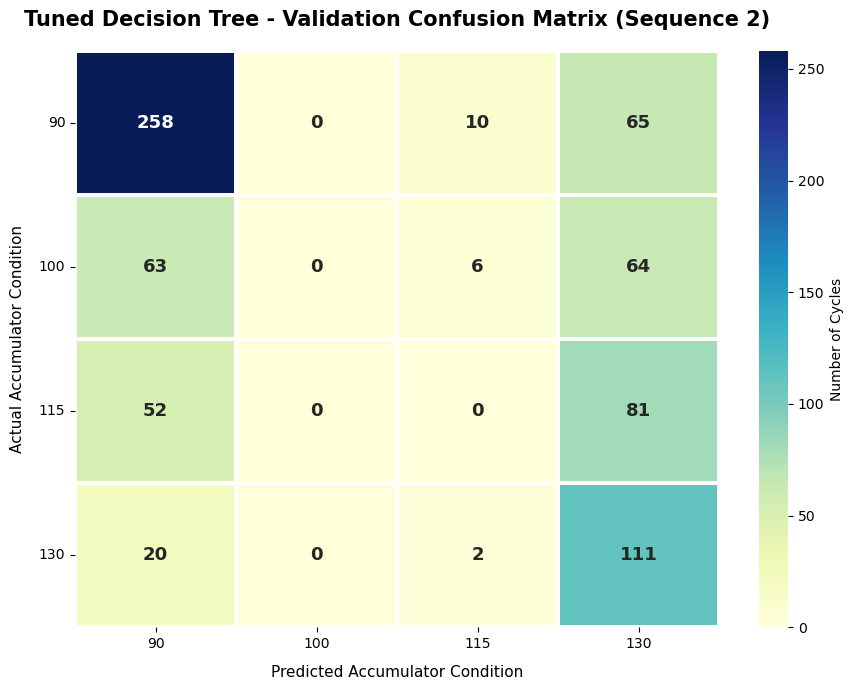

In [44]:
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import confusion_matrix, classification_report
import seaborn as sns
import matplotlib.pyplot as plt

# Create the best tuned Decision Tree

best_tree = DecisionTreeClassifier(
    max_depth=5,
    min_samples_leaf=10,
    class_weight=None,
    random_state=42
)

# Train on Sequence 1

best_tree.fit(X_seq1, y_seq1)

# Predict on Sequence 2

y_pred_tuned = best_tree.predict(X_seq2)

# Display classification report

print("Tuned Decision Tree - Classification Report")

print(classification_report(
    y_seq2,
    y_pred_tuned,
    zero_division=0
))

# Generate confusion matrix

cm = confusion_matrix(
    y_seq2,
    y_pred_tuned,
    labels=[90, 100, 115, 130]
)

# Improved validation confusion matrix

plt.figure(figsize=(9, 7))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="YlGnBu",
    linewidths=1.5,
    linecolor="white",
    xticklabels=[90, 100, 115, 130],
    yticklabels=[90, 100, 115, 130],
    annot_kws={"size": 13, "weight": "bold"},
    cbar_kws={"label": "Number of Cycles"}
)

plt.title(
    "Tuned Decision Tree - Validation Confusion Matrix (Sequence 2)",
    fontsize=15,
    fontweight="bold",
    pad=18
)

plt.xlabel("Predicted Accumulator Condition", fontsize=11, labelpad=10)
plt.ylabel("Actual Accumulator Condition", fontsize=11, labelpad=10)

plt.xticks(fontsize=10)
plt.yticks(fontsize=10, rotation=0)

plt.tight_layout()
plt.show()

### 9.6 Final Evaluation of the Tuned Decision Tree

Based on the hyperparameter tuning experiment, the Decision Tree with a maximum depth of 5 and a minimum of 10 samples per leaf was selected.

The selected model is now retrained using the combined training data from Sequences 1 and 2.

Its final performance is evaluated on Sequence 3, which was not used for model training or hyperparameter tuning.

Accuracy, precision, recall, F1-score and the confusion matrix are used to assess its classification performance.

Final Tuned Decision Tree Performance
Accuracy: 0.28835489833641403
Precision: 0.20949285685447822
Recall: 0.28131949592290584
F1 Score: 0.2234313083405581

Classification Report
              precision    recall  f1-score   support

          90       0.30      0.70      0.42       142
         100       0.24      0.22      0.23       133
         115       0.29      0.20      0.24       133
         130       0.00      0.00      0.00       133

    accuracy                           0.29       541
   macro avg       0.21      0.28      0.22       541
weighted avg       0.21      0.29      0.23       541



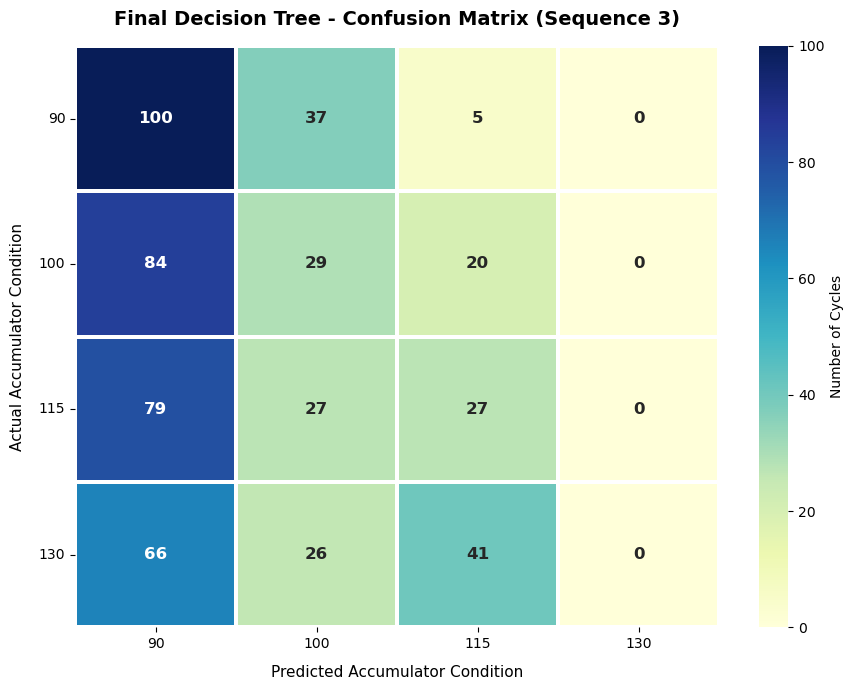

In [45]:
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    confusion_matrix
)
import seaborn as sns
import matplotlib.pyplot as plt

# Create the selected tuned model

final_tree = DecisionTreeClassifier(
    max_depth=5,
    min_samples_leaf=10,
    class_weight=None,
    random_state=42
)

# Train using Sequences 1 and 2

final_tree.fit(X_train, y_train)

# Evaluate on Sequence 3, which was not used for model fitting or hyperparameter tuning

y_pred_final = final_tree.predict(X_test)

# Calculate evaluation metrics

print("Final Tuned Decision Tree Performance")

print("Accuracy:", accuracy_score(y_test, y_pred_final))
print("Precision:", precision_score(
    y_test, y_pred_final,
    average="macro",
    zero_division=0
))
print("Recall:", recall_score(
    y_test, y_pred_final,
    average="macro",
    zero_division=0
))
print("F1 Score:", f1_score(
    y_test, y_pred_final,
    average="macro",
    zero_division=0
))

# Classification report

print("\nClassification Report")

print(classification_report(
    y_test,
    y_pred_final,
    zero_division=0
))

# Confusion matrix

cm = confusion_matrix(
    y_test,
    y_pred_final,
    labels=[90, 100, 115, 130]
)

plt.figure(figsize=(9, 7))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="YlGnBu",
    linewidths=1.5,
    linecolor="white",
    xticklabels=[90, 100, 115, 130],
    yticklabels=[90, 100, 115, 130],
    annot_kws={"size": 12, "weight": "bold"},
    cbar_kws={"label": "Number of Cycles"}
)

plt.title(
    "Final Decision Tree - Confusion Matrix (Sequence 3)",
    fontsize=14,
    fontweight="bold",
    pad=15
)

plt.xlabel("Predicted Accumulator Condition", fontsize=11, labelpad=10)
plt.ylabel("Actual Accumulator Condition", fontsize=11, labelpad=10)

plt.xticks(fontsize=10)
plt.yticks(fontsize=10, rotation=0)

plt.tight_layout()
plt.show()

### 9.7 Final Model Evaluation Findings

The final tuned Decision Tree was evaluated on the
testing dataset (Sequence 3).

The model achieved an accuracy of 28.84% and a
Macro F1-score of 22.34%. Its Macro Precision was
20.95%, while its Macro Recall was 28.13%.

The classification report showed that the model
performed best in identifying condition 90, with
a recall of 70%. However, it failed to correctly
identify condition 130, resulting in a recall of 0%.

These results indicate that the model's ability to
generalise to the final testing sequence was limited.

### 9.8 Feature Importance Analysis

Feature importance is used to identify which sensor measurements contributed most to the decisions made by the final Decision Tree.

The importance scores indicate the relative contribution of each feature to the model's decision-making process. The most important features are visualized to improve model interpretability.

,Feature,Importance
42,FS1_range,0.2341
0,PS1_mean,0.1739
76,VS1_min,0.0782
46,FS2_min,0.0680
53,TS1_max,0.0609
11,PS3_std,0.0529
37,EPS1_rms,0.0461
58,TS2_min,0.0450
54,TS1_range,0.0424
25,PS5_rms,0.0294


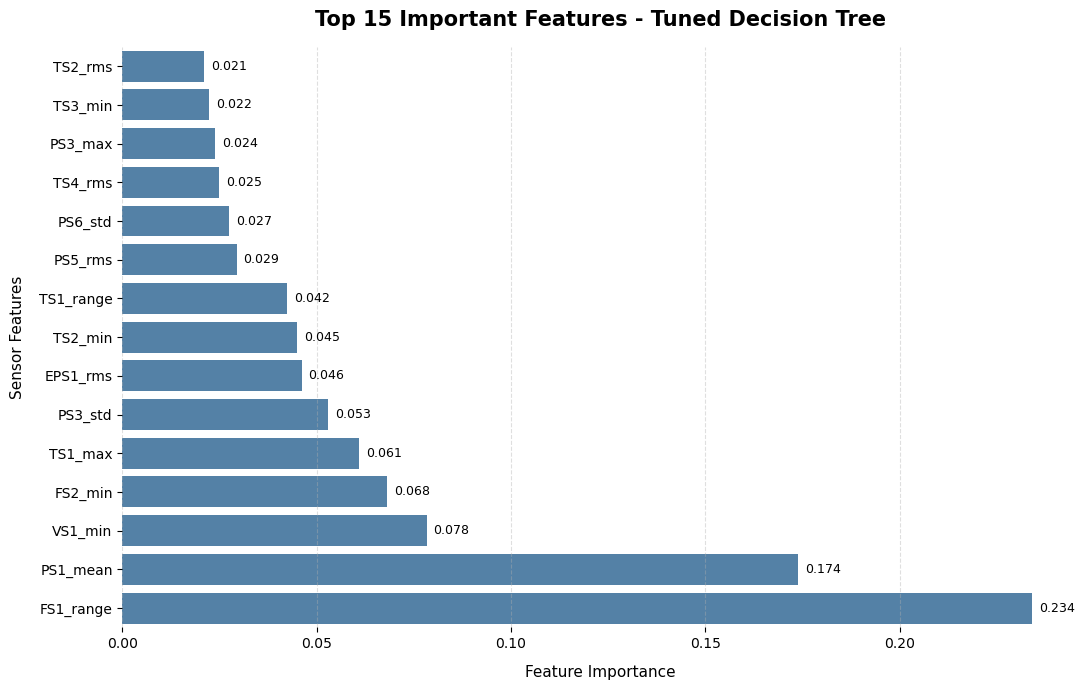

In [46]:
# Extract feature importance from the final Decision Tree

feature_importance = pd.DataFrame({
    "Feature": X_train.columns,
    "Importance": final_tree.feature_importances_
})

# Sort features by importance

feature_importance = feature_importance.sort_values(
    by="Importance",
    ascending=False
)

# Display top 15 features

display(feature_importance.head(15).round(4))


# Plot top 15 features

top_features = feature_importance.head(15).sort_values(
    by="Importance",
    ascending=True
)

plt.figure(figsize=(11, 7))

ax = sns.barplot(
    data=top_features,
    x="Importance",
    y="Feature",
    color="steelblue"
)

for container in ax.containers:
    ax.bar_label(
        container,
        fmt="%.3f",
        padding=5,
        fontsize=9
    )

plt.title(
    "Top 15 Important Features - Tuned Decision Tree",
    fontsize=15,
    fontweight="bold",
    pad=15
)

plt.xlabel("Feature Importance", fontsize=11, labelpad=10)
plt.ylabel("Sensor Features", fontsize=11, labelpad=10)

plt.xticks(fontsize=10)
plt.yticks(fontsize=10)

plt.grid(axis="x", linestyle="--", alpha=0.4)
sns.despine(left=True, bottom=True)

plt.tight_layout()
plt.show()

### 9.9 Feature Importance Findings
The feature importance analysis identified FS1_range
as the most influential feature, with an importance
score of 0.2341, followed by PS1_mean with a score
of 0.1739.

Together, these two features account for approximately
40.8% of the model's total feature importance.

Other influential features included VS1_min, FS2_min,
TS1_max and PS3_std.

These results indicate that flow variation and average
pressure measurements contributed significantly to
the Decision Tree's classification decisions. However,
feature importance reflects the model's reliance on
features and does not establish a causal relationship.

## 10. Model Evaluation and Interpretation

### 10.1 Training vs Testing Performance Analysis

The training and testing performance of the final
Decision Tree model is compared below to assess
how well the model generalises to the final testing
sequence.

In [47]:
from sklearn.metrics import accuracy_score, f1_score

# Predictions on training data
y_train_pred = final_tree.predict(X_train)

# Predictions on testing data
y_test_pred = final_tree.predict(X_test)

# Calculate performance metrics
train_accuracy = accuracy_score(y_train, y_train_pred)
test_accuracy = accuracy_score(y_test, y_test_pred)

train_f1 = f1_score(
    y_train, y_train_pred,
    average="macro",
    zero_division=0
)

test_f1 = f1_score(
    y_test, y_test_pred,
    average="macro",
    zero_division=0
)

# Display comparison
print("Training vs Testing Performance")
print("--------------------------------")
print("Training Accuracy:", round(train_accuracy, 4))
print("Testing Accuracy:", round(test_accuracy, 4))
print("Training Macro F1:", round(train_f1, 4))
print("Testing Macro F1:", round(test_f1, 4))

Training vs Testing Performance
--------------------------------
Training Accuracy: 0.8143
Testing Accuracy: 0.2884
Training Macro F1: 0.7867
Testing Macro F1: 0.2234


The final Decision Tree achieved an accuracy of 81.43%
and a Macro F1-score of 78.67% on the training data.

However, on the testing data (Sequence 3), its accuracy
dropped to 28.84%, and its Macro F1-score was 22.34%.

The substantial gap between training and testing
performance indicates possible overfitting and weak
generalisation to the final sequence. The distribution
differences between the training and testing sequences
may also have contributed to this decline.

Therefore, the model learned patterns from the training
sequences that did not transfer reliably to Sequence 3.

### 10.2 Investigating Sensor Changes Across Cycles

The previous analysis identified substantial differences in sensor measurements between the training and testing datasets.

To understand when these changes occur, the PS4 sensor measurements are plotted against cycle order. This helps identify whether the differences are associated with a change in operating sequence or occur gradually over time.

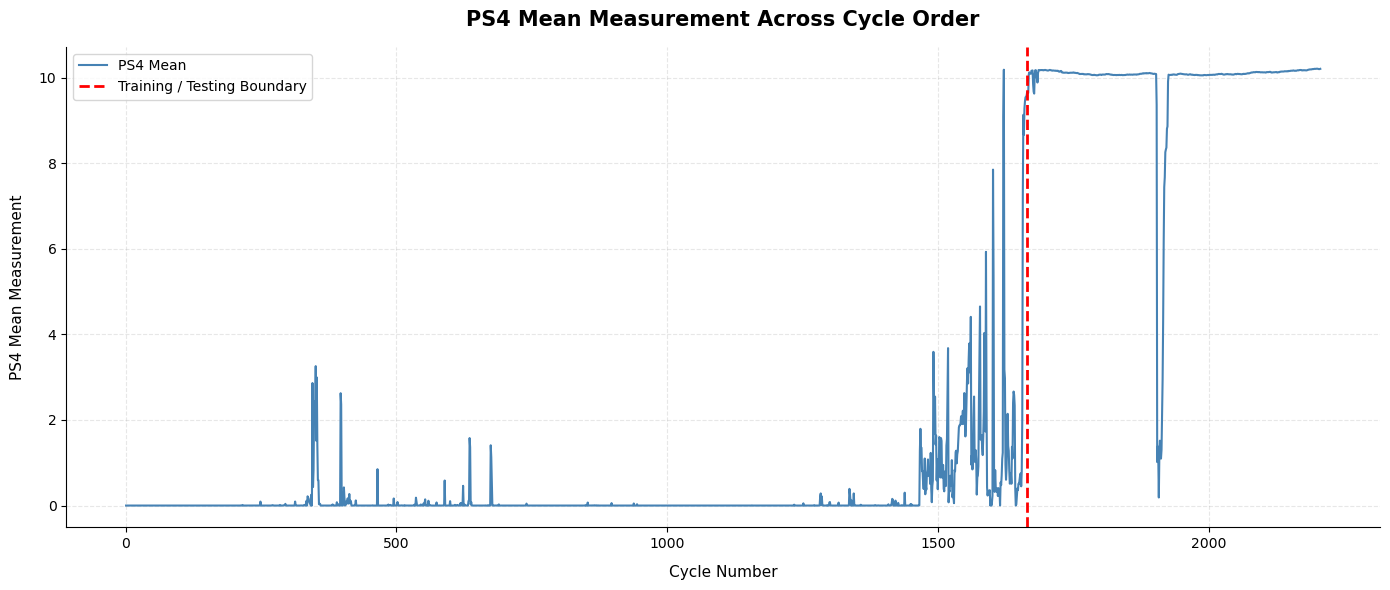

In [48]:
# PS4 sensor trend across cycles

cycle_numbers = df.loc[X.index, "Cycle"]

plt.figure(figsize=(14, 6))

plt.plot(
    cycle_numbers,
    X["PS4_mean"],
    color="steelblue",
    linewidth=1.5,
    label="PS4 Mean"
)

plt.axvline(
    1664,
    color="red",
    linestyle="--",
    linewidth=2,
    label="Training / Testing Boundary"
)

plt.title(
    "PS4 Mean Measurement Across Cycle Order",
    fontsize=15,
    fontweight="bold",
    pad=15
)

plt.xlabel("Cycle Number", fontsize=11, labelpad=10)
plt.ylabel("PS4 Mean Measurement", fontsize=11, labelpad=10)

plt.legend(fontsize=10)
plt.grid(axis="both", linestyle="--", alpha=0.3)
sns.despine()

plt.tight_layout()
plt.show()

In [49]:
# Compare PS4 statistics between training and testing data

for condition in sorted(y_train.unique()):

    train_values = X_train.loc[
        y_train == condition, "PS4_mean"
    ]

    test_values = X_test.loc[
        y_test == condition, "PS4_mean"
    ]

    print(f"\nCondition: {condition}")

    print("Training:")
    print(train_values.describe().round(4))

    print("\nTesting:")
    print(test_values.describe().round(4))


Condition: 90
Training:
count    666.0000
mean       0.5336
std        1.4158
min        0.0000
25%        0.0000
50%        0.0000
75%        0.3983
max       10.1828
Name: PS4_mean, dtype: float64

Testing:
count    142.0000
mean      10.1457
std        0.0317
min       10.0829
25%       10.1226
50%       10.1390
75%       10.1688
max       10.2071
Name: PS4_mean, dtype: float64

Condition: 100
Training:
count    266.0000
mean       0.0110
std        0.0490
min        0.0000
25%        0.0000
50%        0.0000
75%        0.0000
max        0.5846
Name: PS4_mean, dtype: float64

Testing:
count    133.0000
mean      10.0707
std        0.0102
min       10.0506
25%       10.0623
50%       10.0710
75%       10.0783
max       10.0911
Name: PS4_mean, dtype: float64

Condition: 115
Training:
count    266.0000
mean       0.1143
std        0.4734
min        0.0000
25%        0.0000
50%        0.0000
75%        0.0000
max        3.2573
Name: PS4_mean, dtype: float64

Testing:
count    133.0000


### 10.3 Investigating Changes in Other Pressure Sensors

The PS4 analysis revealed a substantial change in sensor measurements around the training/testing boundary.

To determine whether this change is isolated to PS4 or affects other pressure sensors as well, measurements from PS1, PS2, PS3, PS5 and PS6 are also examined across the cycle sequence.

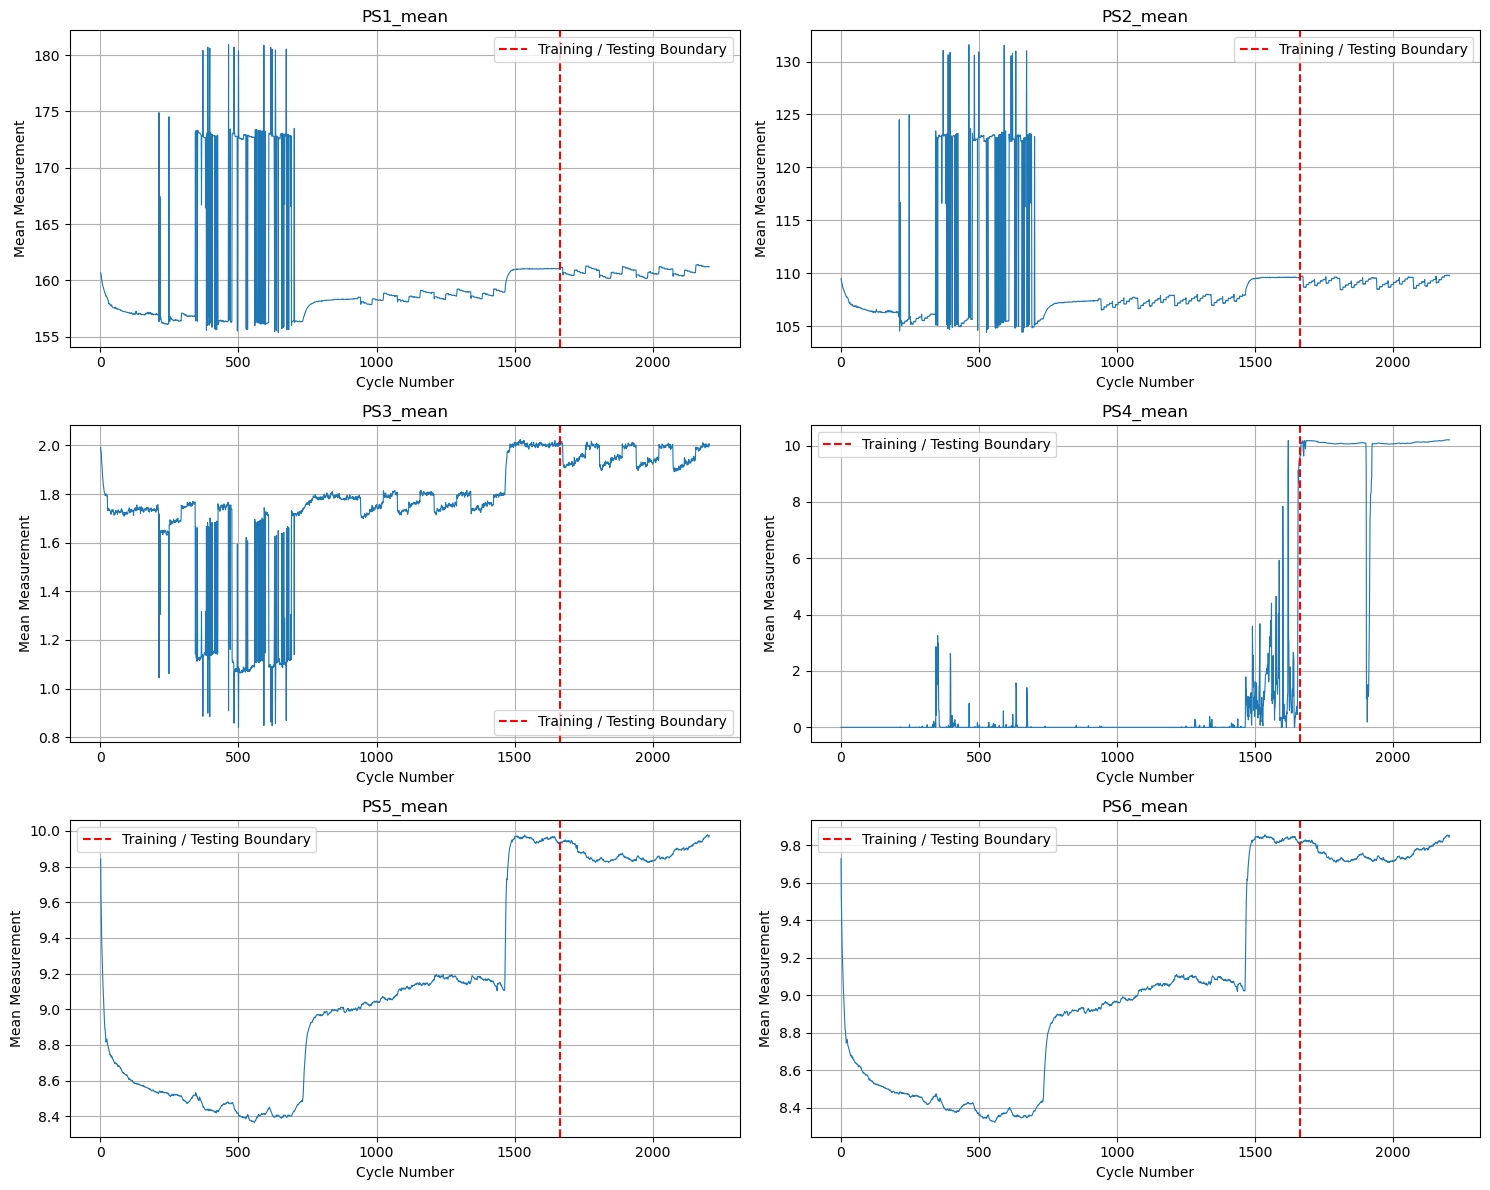

In [50]:
# Compare pressure sensor measurements across cycles

pressure_features = [
    "PS1_mean",
    "PS2_mean",
    "PS3_mean",
    "PS4_mean",
    "PS5_mean",
    "PS6_mean"
]

cycle_numbers = df.loc[X.index, "Cycle"]

fig, axes = plt.subplots(3, 2, figsize=(15, 12))

for i, feature in enumerate(pressure_features):

    ax = axes[i // 2, i % 2]

    ax.plot(cycle_numbers, X[feature], linewidth=0.8)

    ax.axvline(
        1664,
        color="red",
        linestyle="--",
        label="Training / Testing Boundary"
    )

    ax.set_title(feature)
    ax.set_xlabel("Cycle Number")
    ax.set_ylabel("Mean Measurement")
    ax.grid(True)
    ax.legend()

plt.tight_layout()
plt.show()

### 10.4 Comparing Sensor Behaviour Across Operating Sequences

The previous visualizations showed that several pressure sensors change their measurement patterns over time.

To investigate this further, the average measurements of PS1 to PS6 are compared across the three operating sequences for each accumulator condition.

This comparison helps determine whether the sensor behaviour associated with the same accumulator condition remains consistent across different sequences.

In [51]:
# Assign each cycle to its operating sequence

cycle_numbers = df.loc[X.index, "Cycle"]

sequence = pd.Series(index=X.index, dtype="object")

sequence.loc[cycle_numbers <= 932] = "Sequence 1"
sequence.loc[(cycle_numbers > 932) & (cycle_numbers <= 1664)] = "Sequence 2"
sequence.loc[cycle_numbers > 1664] = "Sequence 3"

# Select pressure sensor mean features

pressure_features = [
    "PS1_mean",
    "PS2_mean",
    "PS3_mean",
    "PS4_mean",
    "PS5_mean",
    "PS6_mean"
]

# Combine sensor measurements and labels

sequence_data = X[pressure_features].copy()

sequence_data["Condition"] = y
sequence_data["Sequence"] = sequence

# Calculate average sensor measurements

sequence_summary = sequence_data.groupby(
    ["Sequence", "Condition"]
)[pressure_features].mean().round(4)

display(sequence_summary)

PS1_mean  PS2_mean  PS3_mean  PS4_mean  PS5_mean  \
Sequence   Condition                                                     
Sequence 1 90         161.0809  110.3223    1.6176    0.0220    8.7418   
           100        167.7260  117.4248    1.2747    0.0140    8.4083   
           115        165.3243  114.8702    1.4132    0.2286    8.4615   
           130        157.3082  106.5123    1.7220    0.0010    8.6138   
Sequence 2 90         160.0778  108.7158    1.9056    1.0453    9.6208   
           100        158.7574  107.5093    1.7654    0.0079    9.1709   
           115        158.5724  107.3325    1.7670    0.0000    9.1257   
           130        158.3430  107.1746    1.7557    0.0006    9.0417   
Sequence 3 90         160.8887  109.2441    1.9522   10.1457    9.9173   
           100        160.6977  109.0821    1.9549   10.0707    9.8420   
           115        160.6810  109.0635    1.9589    9.1814    9.8431   
           130        160.8340  109.2105    1.9597   10.0993    9.8941   

                      PS6_mean  
Sequence   Condition            
Sequence 1 90           8.6785  
           100          8.3621  
           115          8.4105  
           130          8.5535  
Sequence 2 90           9.5156  
           100          9.0857  
           115          9.0416  
           130          8.9639  
Sequence 3 90           9.7985  
           100          9.7267  
           115          9.7283  
           130          9.7765

### 10.5 Findings from Operating Sequence Comparison

The comparison of sensor measurements across the three operating sequences revealed substantial changes in sensor behaviour, even for the same accumulator condition.

The PS4 sensor showed the most significant change, with its mean measurements increasing considerably across the sequences. PS5 and PS6 also demonstrated an increasing trend, while PS1, PS2 and PS3 showed changes in their measurement patterns.

These findings indicate that the sensor feature distributions are dependent on the operating sequence. Consequently, models trained on earlier sequences may struggle to generalize to a later sequence.

This distribution shift is a likely contributor to the poor testing performance observed during model evaluation. Further investigation is required before determining the physical cause of these changes.

### 10.6 Distribution Shift Analysis

Distribution shift occurs when the statistical characteristics of data change between the training and testing datasets.

In this project, the model is trained using Sequences 1 and 2 and tested on Sequence 3.

Comparing sensor measurements across these sequences helps identify differences in data distributions that may affect the model's ability to generalise to unseen operating conditions.

In [52]:
# Compare sensor feature distributions within each condition

for condition in sorted(y_train.unique()):

    train_class = X_train.loc[y_train == condition]
    test_class = X_test.loc[y_test == condition]

    train_mean = train_class.mean()
    test_mean = test_class.mean()

    train_std = train_class.std()
    test_std = test_class.std()

    pooled_std = np.sqrt(
        (train_std ** 2 + test_std ** 2) / 2
    )

    smd = (
        (test_mean - train_mean) /
        pooled_std.replace(0, np.nan)
    ).abs()

    shift_table = pd.DataFrame({
        "Training Mean": train_mean,
        "Testing Mean": test_mean,
        "Absolute SMD": smd
    })

    shift_table = shift_table.sort_values(
        "Absolute SMD", ascending=False
    )

    print(f"\nCondition: {condition}")
    display(shift_table.head(10).round(4))


Condition: 90


,Training Mean,Testing Mean,Absolute SMD
PS4_min,0.2778,10.0698,12.4730
PS4_mean,0.5336,10.1457,9.5989
PS4_rms,0.6179,10.1457,9.0181
PS4_max,1.6913,10.2062,4.4839
PS3_max,10.3447,9.4457,2.3450
EPS1_min,2262.4610,2351.7141,2.0799
EPS1_max,2896.2288,2962.6014,2.0664
PS1_range,47.3961,45.3168,2.0411
PS6_min,9.0359,9.7337,1.8922
PS5_min,9.1214,9.8533,1.8875



Condition: 100


,Training Mean,Testing Mean,Absolute SMD
PS4_min,0.0000,9.9951,1261.3841
PS4_mean,0.0110,10.0707,284.4804
PS4_rms,0.0470,10.0707,84.4047
PS4_max,0.5268,10.1306,10.2270
PS3_max,10.6860,9.6768,4.7494
EPS1_range,643.8368,612.2511,4.7160
PS1_range,48.3175,45.4449,4.0059
PS6_min,8.6653,9.6609,3.9509
PS5_min,8.7332,9.7794,3.9207
PS6_mean,8.7239,9.7267,3.9038



Condition: 115


,Training Mean,Testing Mean,Absolute SMD
EPS1_range,644.8248,612.5970,5.6520
PS3_max,10.7493,9.7377,5.6372
PS4_mean,0.1143,9.1814,5.1143
PS4_rms,0.2321,9.2015,4.9905
PS1_range,48.3267,45.4654,4.6777
PS6_min,8.6684,9.6621,4.5078
PS5_min,8.7361,9.7810,4.4970
PS6_mean,8.7261,9.7283,4.4674
PS6_rms,8.7261,9.7284,4.4674
PS4_min,0.0000,8.9218,4.4507



Condition: 130


,Training Mean,Testing Mean,Absolute SMD
PS4_mean,0.0009,10.0993,149.0163
PS4_rms,0.0059,10.0995,137.0095
PS4_min,0.0000,9.9807,74.6915
PS4_max,0.0935,10.1775,23.4691
PS5_min,8.6757,9.8305,6.7208
PS6_min,8.6093,9.7105,6.6808
PS5_mean,8.7359,9.8941,6.6717
PS5_rms,8.7360,9.8942,6.6715
PS6_mean,8.6706,9.7765,6.6448
PS6_rms,8.6707,9.7765,6.6446


The analysis revealed substantial differences in sensor measurements across the three operating sequences.

For example, `PS4_mean` showed a considerable change for condition 90, increasing from approximately 0.5336 in the training data to 10.1457 in the testing data.

Similar differences were observed across other accumulator conditions, indicating a significant distribution shift between the training and testing sequences.

These changes may have affected the Decision Tree's ability to generalise to Sequence 3, potentially contributing to its reduced testing performance.

This highlights the importance of considering changes in operating conditions when evaluating machine learning models on sequential sensor data.

### 10.7 Overall Model Evaluation

The tuned Decision Tree was selected as the final model based on its validation performance.

It achieved 28.84% accuracy and a 22.34% Macro F1-score on the testing data (Sequence 3).

Although the selected configuration performed slightly better than the initial Decision Tree on the validation data, its testing results indicate limited generalisation to the final sequence.

The distribution shift observed across the operating sequences may have contributed to this performance decline.

The model performed better at identifying condition 90 but struggled to correctly classify condition 130.

Overall, these findings demonstrate the challenges of predicting hydraulic accumulator conditions when sensor data distributions change. The model should not be considered sufficiently reliable for practical deployment without further investigation and improvement.

## 11. Ethical Considerations and Limitations

### 11.1 Ethical Considerations

This project uses a publicly available dataset from the UCI Machine Learning Repository. It contains sensor measurements from hydraulic systems rather than personal or identifiable information.

One important ethical consideration is the reliability of model predictions. Incorrectly predicting an accumulator's condition could lead to inappropriate maintenance decisions or overlooked equipment problems.

Therefore, the model should be treated as a decision-support tool rather than a replacement for expert inspection. Predictions should be verified before any maintenance action is taken.

The model's limited performance on unseen data also highlights the importance of transparent reporting and avoiding unsupported claims about its reliability.

### 11.2 Project Limitations

The project has the following limitations:

1. **Limited dataset:** The model is trained and evaluated using one publicly available hydraulic system dataset. Its performance on other hydraulic systems has not been established.

2. **Distribution shift:** Sensor measurements differ considerably between the training and testing sequences, affecting the model's ability to generalise.

3. **Overfitting:** The Decision Tree performs considerably better on training data than on unseen testing data.

4. **Class-wise performance:** The model does not predict all four accumulator conditions equally well. In particular, it struggles to identify the optimal pressure condition (class 130).

5. **Deployment limitations:** The model has not been tested in a real-time industrial environment and should not be used independently for maintenance decisions.

## 12. Conclusion

This project explored the use of machine learning to predict hydraulic accumulator conditions using sensor measurements collected from a hydraulic system.

The dataset was analysed, cleaned and preprocessed before training and comparing Logistic Regression, Decision Tree and Random Forest models. A chronological data split was used to preserve the sequence of observations. Hyperparameter tuning was then performed to select a suitable Decision Tree configuration based on validation performance.

The final tuned Decision Tree, with a maximum depth of 5 and a minimum of 10 samples per leaf, achieved **28.84% accuracy and a 22.34% Macro F1-score** on Sequence 3. The results showed that the model performed better at identifying condition 90, with a recall of 70%, but failed to correctly identify condition 130, resulting in a recall of 0%. Overall, its ability to generalise to the final sequence remained limited.

The feature importance analysis identified `FS1_range` and `PS1_mean` as the two most influential features in the final model, suggesting that flow variations and average pressure measurements played important roles in its classification decisions. However, feature importance does not establish a causal relationship.

The distribution shift analysis revealed substantial differences in sensor measurements between the training and testing sequences. These differences may have contributed to the model's reduced generalisation performance.

Overall, this project demonstrated the machine learning workflow, from data exploration and preprocessing to model comparison, hyperparameter tuning, evaluation and interpretation. It also highlighted the challenges of applying machine learning to sequential industrial sensor data, particularly when operating conditions change over time.

Further improvements could include investigating the causes of distribution shift, exploring additional classification algorithms, applying suitable approaches to handle changing operating conditions and evaluating the model on data collected from other hydraulic systems.

In [53]:

from pathlib import Path
import pandas as pd

# Create the Streamlit data folder
output_folder = Path("streamlit_dashboard/data")
output_folder.mkdir(parents=True, exist_ok=True)

# 1. Sensor Data
sensor_data = X.copy()
sensor_data.insert(0, "Cycle", df.loc[X.index, "Cycle"])
sensor_data["Accumulator_Condition"] = y

sensor_data.to_csv(output_folder / "Sensor_Data.csv", index=False)

# 2. Model Comparison
model_comparison = pd.DataFrame({
    "Model": [
        "Dummy Classifier",
        "Logistic Regression",
        "Decision Tree",
        "Random Forest"
    ],
    "Accuracy": [0.4549, 0.4932, 0.5014, 0.1380],
    "Macro Precision": [0.1137, 0.3682, 0.2496, 0.0611],
    "Macro Recall": [0.2500, 0.3038, 0.4008, 0.0815],
    "Macro F1": [0.1563, 0.2499, 0.2985, 0.0694]
})

model_comparison.to_csv(output_folder / "Model_Comparison.csv", index=False)

# 3. Final Predictions
final_predictions = pd.DataFrame({
    "Cycle": df.loc[y_test.index, "Cycle"],
    "Actual_Condition": y_test,
    "Predicted_Condition": y_pred_final
})

final_predictions["Prediction_Correct"] = (
    final_predictions["Actual_Condition"] ==
    final_predictions["Predicted_Condition"]
)

final_predictions.to_csv(output_folder / "Final_Predictions.csv", index=False)

# 4. Feature Importance
feature_importance = pd.DataFrame({
    "Feature": X_train.columns,
    "Importance": final_tree.feature_importances_
}).sort_values(by="Importance", ascending=False)

feature_importance.to_csv(output_folder / "Feature_Importance.csv", index=False)

print("All four CSV files exported successfully!")
print("Location:", output_folder.resolve())


All four CSV files exported successfully!
Location: C:\PROJECTS\Hydrolic condition prediction\notebooks\streamlit_dashboard\data
